# MOF crystal habit from CHGNet surface energies: pipeline steps 1–8

Runs entirely in Colab: CIFs are downloaded (RASPA2 structure library on GitHub, or CoRE MOF 2019 on Zenodo by CSD refcode), models are downloaded by pip.

| Step | What runs here |
|---|---|
| 1 Standardize | conventional + working cell; disorder policy (`majority` / `reject`), overlapping split sites merged, free guests removed, formula / lattice / space group stored. If H or OH ordering breaks the symmetry, the point group comes from the H-free or metal+C skeleton (logged). |
| 2 Building blocks | one bond rule set for all steps; nodes (metal + oxo/OH + M–M) vs linkers; unwrapped coordinates and centroids; infinite rods/sheets detected and flagged |
| 3 Faces + terminations | symmetry-unique {hkl} families from the real point group (h' = hR⁻¹, Laue class), ranked by d_hkl (BFDH), not a fixed cubic list; terminations = distinct block-centroid levels, duplicates removed; if more than `MAX_TERMS`, the ones breaking fewest bonds per area are kept |
| 4 Slabs | whole blocks only; stoichiometry **asserted** (atom count = n × OUC, same reduced formula); vacuum. Neutral by construction (whole blocks, no charge transfer) |
| 5 Healing | **on by default**. Every broken bond is found by comparing each slab atom with its bulk image; each broken bond gets one H₂O, split heterolytically (OH⁻ on the metal, H⁺ on the donor O/N). Terminations that break organic or M–M bonds, or are unbalanced, are rejected. Intact slabs are kept (old bug fixed). |
| 6 Surface energies | CHGNet; bulk relaxed at fixed cell with the same settings; all terminations screened statically, the `RELAX_TOP_K` lowest relaxed (fmax and step limit logged); γ = (E_slab − N·e_bulk − n·E_H₂O)/2A; lowest converged γ per family; unconverged slabs excluded and listed |
| 7 Validation | (a) independent MLIP (MACE-MP-0) re-scores the CHGNet geometries: rank correlation and MAE; (b) CP2K PBE-D3(BJ) inputs for a small held-out set; (c) upload DFT energies → MAE / Spearman / failures. **DFT itself cannot run in Colab** for 300–600-atom slabs. 7(a) is a cross-check, not DFT. |
| 8 Wulff | Wulff polyhedron built from the true point group (pymatgen's WulffShape uses lattice symmetry, wrong for non-cubic MOFs); area fractions; habit name (cubic polyhedra, or rod / plate / prism for others); open (unbounded) directions reported; 3D PNG and OBJ per MOF |

**Runtime (Colab T4 GPU):** roughly 15–40 min per MOF with full relaxation. Fill `ONLY` with one MOF name to test first. Results are cached, so a rerun only computes what is missing. Turn on `SAVE_TO_DRIVE` to survive disconnects.

In [ ]:
# 1. Install (about 2 min). Restarts the runtime once if numpy was upgraded; then use Runtime > Run all again.
import importlib.util, subprocess, sys, os
if importlib.util.find_spec("chgnet") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "chgnet>=0.3.0", "pymatgen", "networkx"], check=True)
    import importlib.metadata as md
    if "numpy" in sys.modules and sys.modules["numpy"].__version__ != md.version("numpy"):
        print("numpy was upgraded: restarting runtime. Run all cells again."); os.kill(os.getpid(), 9)
import torch, chgnet, pymatgen.core
print("chgnet", chgnet.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("No GPU: Runtime > Change runtime type > T4 GPU (CPU works but is ~10x slower).")

chgnet 0.4.2 | torch 2.14.1+cu130 | GPU: True


In [3]:
# 2. Output folder (optionally on Google Drive)
SAVE_TO_DRIVE = True  #@param {type:"boolean"}
OUT_DIR = "/content/results"
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive/mof_wulff_results"
os.makedirs(OUT_DIR, exist_ok=True); print("results ->", OUT_DIR)

Mounted at /content/drive
results -> /content/drive/MyDrive/mof_wulff_results


In [4]:
%%writefile /content/mofwulff.py
"""MOF crystal habit from machine-learned surface energies (pipeline steps 1-8).

Step 1  standardize()        read CIF, disorder/overlap/guest policy, symmetry, conv + working cell
Step 2  building_blocks()    metal nodes vs organic linkers, unwrapped, periodic-node detection
Step 3  face_families()      symmetry-unique {hkl} families + distinct block terminations
Step 4  block_slabs()        whole-block, stoichiometric slabs (asserted), vacuum
Step 5  heal()               heterolytic H2O capping of every broken metal-ligand bond (H+ to ligand, OH- to metal)
Step 6  CHGNet energies      bulk relaxed at fixed cell; static screen of all terminations, relax lowest K
Step 7  validation helpers   independent-model (MACE-MP-0) re-scoring, CP2K PBE-D3 inputs, DFT comparison
Step 8  wulff()              Wulff polyhedron from true point-group symmetry, area fractions, habit name, 3D render

Every rule that discards or caps something is written in a docstring and logged in the outputs.
"""
import hashlib, itertools, json, math, re, time, warnings
from collections import Counter
from math import gcd
from pathlib import Path

import networkx as nx
import numpy as np
from pymatgen.core import Element, Lattice, Molecule, Structure
from pymatgen.core.surface import SlabGenerator
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

warnings.filterwarnings("ignore")
EV_A2_TO_J_M2 = 16.0218

# ----------------------------------------------------------------------------- bonding rules
# One set of rules, used by every step (blocks, slabs, healing, coordination counts).
ORGANIC = {("C", "C"): 1.65, ("C", "O"): 1.50, ("C", "H"): 1.20, ("C", "N"): 1.60, ("N", "H"): 1.15,
           ("O", "H"): 1.15, ("N", "N"): 1.50, ("C", "S"): 1.90, ("C", "F"): 1.45, ("C", "Cl"): 1.85,
           ("C", "Br"): 2.00, ("B", "O"): 1.60, ("B", "C"): 1.70, ("P", "O"): 1.70, ("S", "O"): 1.60}
DONORS = {"O", "N", "S", "F", "Cl"}       # atoms that can bind a metal
M_X = 2.55                                # metal-donor bond cutoff, A
M_M = 2.80                                # metal-metal bond cutoff, A (Cu2 paddlewheel 2.6; Mg...Mg in MOF-74 rods ~2.9 is not a bond)
OUT_REACH = 3.0                           # neighbour search radius, A


def is_metal(el):
    e = Element(el)
    return e.is_metal or el in {"Ge", "Sb"}  # Element.is_metal covers alkali..post-transition


def _org(a, b):
    return ORGANIC.get((a, b), ORGANIC.get((b, a)))


def bond_kind(a, b, d, lig_a=False, lig_b=False):
    """Classify a pair: 'org', 'MM', 'ML' (metal-ligand donor), 'MO' (metal-oxo/hydroxo/aqua donor) or None."""
    ma, mb = is_metal(a), is_metal(b)
    if ma and mb:
        return "MM" if d <= M_M else None
    if ma or mb:
        x, lx = (b, lig_b) if ma else (a, lig_a)
        if x in DONORS and d <= M_X:
            return "ML" if lx else "MO"
        return None
    r = _org(a, b)
    return "org" if r is not None and d <= r else None


def ligand_donors(s, nbs=None):
    """Indices of donor atoms bonded to C (carboxylate O, imidazolate N, ...): they belong to linkers."""
    nbs = nbs if nbs is not None else s.get_all_neighbors(OUT_REACH)
    sym = [x.specie.symbol for x in s]
    return {i for i in range(len(s)) if sym[i] in DONORS
            and any(n.specie.symbol == "C" and n.nn_distance <= _org(sym[i], "C") for n in nbs[i])}


def bond_counts(s, lig, nbs=None):
    """Per-site Counter of bond kinds. lig = set of ligand donor indices of s."""
    nbs = nbs if nbs is not None else s.get_all_neighbors(OUT_REACH)
    sym = [x.specie.symbol for x in s]
    out = []
    for i in range(len(s)):
        c = Counter()
        for n in nbs[i]:
            k = bond_kind(sym[i], sym[n.index], n.nn_distance, i in lig, n.index in lig)
            if k:
                c[k] += 1
        out.append(c)
    return out


# ----------------------------------------------------------------------------- step 1
def standardize(cif, symprec=0.1, disorder="majority", remove_guests=True, overlap_tol=0.6):
    """Read and clean a CIF.

    Disorder policy (documented, logged in notes):
      'reject'   : any partial occupancy -> error.
      'majority' : each disordered site keeps its highest-occupancy species; sites with total
                   occupancy < 0.5 are removed. Pairs of sites closer than overlap_tol (split
                   positions written as full occupancy) are merged, keeping the first.
    Guests: connected components with no metal and no bond to the framework (free solvent)
            are removed when remove_guests is True.
    Symmetry: tried on (a) full structure, (b) without H, (c) metals + C only. The highest
            space group found defines the point group used for face families. If (a) has it,
            conventional + primitive standard cells are used (slabs from the primitive cell).
            If only a skeleton has it (ordered H / ordered OH breaking symmetry in the CIF),
            the input cell is used as both cells, with the skeleton's operations.
    """
    notes = []
    s = Structure.from_file(cif)
    if not s.is_ordered:
        n_dis = sum(1 for site in s if not site.is_ordered)
        if disorder == "reject":
            raise ValueError(f"{n_dis} partially occupied sites; disorder policy is 'reject'")
        sp, fc, drop = [], [], 0
        for site in s:
            occ = site.species.num_atoms
            if occ < 0.5:
                drop += 1
                continue
            el = max(site.species.items(), key=lambda kv: kv[1])[0]
            sp.append(el.symbol if hasattr(el, "symbol") else str(el)); fc.append(site.frac_coords)
        s = Structure(s.lattice, sp, fc)
        notes.append(f"disorder: {n_dis} partial sites -> majority species, {drop} low-occupancy sites removed")
    # overlapping split sites
    dm = s.distance_matrix
    np.fill_diagonal(dm, 99)
    close = sorted({max(i, j) for i, j in zip(*np.where(dm < overlap_tol))})
    if close:
        s.remove_sites(close)
        notes.append(f"overlap: {len(close)} sites closer than {overlap_tol} A to another site removed")
    # free guests
    if remove_guests:
        nbs = s.get_all_neighbors(OUT_REACH)
        lig = ligand_donors(s, nbs)
        sym = [x.specie.symbol for x in s]
        G = nx.Graph(); G.add_nodes_from(range(len(s)))
        for i in range(len(s)):
            for n in nbs[i]:
                if bond_kind(sym[i], sym[n.index], n.nn_distance, i in lig, n.index in lig):
                    G.add_edge(i, n.index)
        guests = [c for c in nx.connected_components(G) if not any(is_metal(sym[i]) for i in c)]
        if guests:
            idx = sorted(i for c in guests for i in c)
            formulas = Counter(Structure(s.lattice, [sym[i] for i in c], [s[i].frac_coords for i in c])
                               .composition.reduced_formula for c in guests)
            s.remove_sites(idx)
            notes.append(f"guests removed: {dict(formulas)}")
    # symmetry
    def sg(st):
        try:
            a = SpacegroupAnalyzer(st, symprec=symprec)
            return a.get_space_group_number(), a
        except Exception:
            return 1, None
    full_n, full_a = sg(s)
    noH = s.copy(); noH.remove_species(["H"])
    mc = s.copy(); mc.remove_species([e for e in {x.specie.symbol for x in s} if not (is_metal(e) or e == "C")])
    cands = [("full", full_n, full_a, s), ("no_H", *sg(noH), noH), ("metal+C", *sg(mc), mc)]
    best = max(cands, key=lambda c: c[1])
    if best[0] == "full" or full_n == best[1]:
        conv = full_a.get_conventional_standard_structure()
        # primitive cell in the SAME cartesian frame as conv (needed for exact Miller conversion)
        prim = conv.get_primitive_structure(tolerance=0.25)
        if len(prim) != len(full_a.get_primitive_standard_structure()):
            prim = conv
            notes.append("primitive reduction in the conventional frame failed; conventional cell used for slabs")
        ops = SpacegroupAnalyzer(conv, symprec=symprec).get_symmetry_operations()
        sym_src, cs, sgsym = "full", full_a.get_crystal_system(), full_a.get_space_group_symbol()
    else:
        conv = prim = s
        ops = best[2].get_symmetry_operations()
        sym_src, cs, sgsym = best[0], best[2].get_crystal_system(), best[2].get_space_group_symbol()
        notes.append(f"symmetry: full structure is SG {full_n}; skeleton '{best[0]}' is {sgsym}; "
                     f"input cell used, skeleton point group used for face families")
    rots = []
    for op in ops:
        R = np.round(op.rotation_matrix).astype(int)
        if not any(np.array_equal(R, q) for q in rots):
            rots.append(R)
    return dict(structure=s, conv=conv, prim=prim, rotations=rots, space_group=sgsym,
                symmetry_source=sym_src, crystal_system=cs, formula=s.composition.reduced_formula,
                n_atoms_conv=len(conv), n_atoms_prim=len(prim), notes=notes)


# ----------------------------------------------------------------------------- step 2
def building_blocks(s):
    """Split a periodic structure into building blocks.

    node   = metal atoms + donors bonded only to metals (oxo/hydroxo/aqua), joined by M-M and M-oxo bonds
    linker = connected organic piece (ORGANIC bonds), including its donor atoms
    Only 'ML' bonds (metal - ligand donor) are ever cut between blocks.
    A block that wraps onto itself through a lattice translation is an infinite (rod/sheet)
    inorganic unit; it is cut at the cell boundary and flagged (periodic_dirs, cartesian).
    """
    nbs = s.get_all_neighbors(OUT_REACH)
    lig = ligand_donors(s, nbs)
    sym = [x.specie.symbol for x in s]
    G = nx.MultiGraph(); G.add_nodes_from(range(len(s)))
    for i in range(len(s)):
        for n in nbs[i]:
            k = bond_kind(sym[i], sym[n.index], n.nn_distance, i in lig, n.index in lig)
            if k and k != "ML" and i <= n.index:
                G.add_edge(i, n.index, img=np.array(n.image, int))
    frac = s.frac_coords
    blocks = []
    for comp in nx.connected_components(G):
        comp = sorted(comp); root = comp[0]
        off = {root: np.zeros(3, int)}; stack = [root]
        while stack:
            u = stack.pop()
            for _, v, data in G.edges(u, data=True):
                img = data["img"] if u <= v else -data["img"]
                if u == v:
                    continue
                if v not in off:
                    off[v] = off[u] + img; stack.append(v)
        per = set()
        for u, v, data in G.subgraph(comp).edges(data=True):
            i, j = min(u, v), max(u, v)
            t = off[i] + data["img"] - off[j]
            if np.any(t):
                per.add(tuple(int(x) for x in t))
        f = np.array([frac[i] + off[i] for i in comp])
        cart = s.lattice.get_cartesian_coords(f)
        blocks.append(dict(atoms=comp, species=[sym[i] for i in comp], cart=cart, centroid=cart.mean(0),
                           kind="node" if any(is_metal(sym[i]) for i in comp) else "linker",
                           formula=Structure(s.lattice, [sym[i] for i in comp], f).composition.formula.replace(" ", ""),
                           periodic_dirs=[s.lattice.get_cartesian_coords(np.array(t)).tolist() for t in per]))
    return blocks, lig


def summarize_blocks(blocks):
    c = Counter((b["kind"], b["formula"]) for b in blocks)
    per = any(b["periodic_dirs"] for b in blocks)
    return {"blocks": {f"{k}:{f}": n for (k, f), n in c.items()}, "infinite_inorganic_unit": per}


# ----------------------------------------------------------------------------- step 3
def _reduce(v):
    v = np.array(v, int); g = gcd(gcd(abs(v[0]), abs(v[1])), abs(v[2]))
    return tuple(int(x) for x in v // g)


def face_families(conv, rotations, max_index=1, n_keep=6, faces=None):
    """Symmetry-unique face families.

    Miller indices transform as h' = h R^-1 for each point operation R (fractional), plus
    inversion (h and -h are the two sides of one slab, so families follow the Laue class).
    All primitive hkl with |h|,|k|,|l| <= max_index are grouped; the n_keep families with the
    largest interplanar spacing d_hkl are kept (BFDH ranking; documented, not random).
    faces: optional explicit list of hkl, which overrides the enumeration.
    """
    Rinv = [np.round(np.linalg.inv(R)).astype(int) for R in rotations]
    def orbit(h):
        out = set()
        for Ri in Rinv:
            hp = tuple(int(x) for x in np.array(h) @ Ri)
            out.add(hp); out.add(tuple(-x for x in hp))
        return sorted(out)
    if faces:
        cand = [_reduce(h) for h in faces]
    else:
        rng = range(-max_index, max_index + 1)
        cand = [h for h in itertools.product(rng, rng, rng) if any(h) and _reduce(h) == h]
    fams, seen = [], set()
    for h in cand:
        if h in seen:
            continue
        orb = orbit(h); seen.update(orb)
        rep = max(orb)                      # canonical representative: lexicographically largest
        d = conv.lattice.d_hkl(rep)
        fams.append(dict(rep=rep, members=orb, d_hkl=d, name="{" + "".join(map(str, rep)).replace("-", "̅") + "}",
                         key="".join(str(x) for x in rep).replace("-", "m")))
    fams.sort(key=lambda f: -f["d_hkl"])
    return fams if faces else fams[:n_keep]


# ----------------------------------------------------------------------------- step 4
def primitive_miller(conv, prim, hkl):
    """Conventional (hkl) -> integer Miller indices of the same plane in the primitive cell."""
    if conv is prim:
        return tuple(hkl)
    g = np.array(hkl, float) @ conv.lattice.reciprocal_lattice_crystallographic.matrix
    hp = prim.lattice.matrix @ g
    hp = hp / np.abs(hp[np.abs(hp) > 1e-6]).min()
    for m in range(1, 25):
        v = hp * m
        if np.allclose(v, np.round(v), atol=1e-3):
            return _reduce(np.round(v).astype(int))
    raise ValueError(f"cannot convert {hkl} to the primitive cell")


def _surface_fingerprint(blocks_in_slab, z, top, bottom, depth=4.0):
    t = sorted(f for f, zc in blocks_in_slab if zc > top - depth)
    b = sorted(f for f, zc in blocks_in_slab if zc < bottom + depth)
    return tuple(sorted([tuple(t), tuple(b)]))


def block_slabs(conv, prim, hkl, min_thickness=15.0, vacuum=15.0, level_tol=0.3):
    """All distinct whole-block slabs for conventional (hkl).

    Oriented unit cell (OUC) of the working cell; h = lattice repeat along the normal.
    A block copy is kept if its centroid height lies in [z0, z0 + n*h); every block type repeats
    with period h, so the slab holds exactly n copies of the OUC -> stoichiometric for any z0
    (asserted below). Terminations: one z0 just below each distinct centroid level (levels closer
    than level_tol merged). Duplicate terminations (same block formulas within 4 A of both
    surfaces) are removed.
    Returns list of dicts with slab, orig (OUC index per slab atom), OUC, metadata.
    """
    # oriented unit cell from the primitive and from the conventional cell; the smaller one is used
    opts = [(conv, tuple(hkl))]
    try:
        opts.append((prim, primitive_miller(conv, prim, hkl)))
    except ValueError:
        pass
    cells = [(SlabGenerator(cell, h_, 10, 10, primitive=False).oriented_unit_cell, h_) for cell, h_ in opts]
    ouc, hp = min(cells, key=lambda x: len(x[0]))
    a, b, c = ouc.lattice.matrix
    nrm = np.cross(a, b); nrm /= np.linalg.norm(nrm)
    h = float(np.dot(c, nrm))
    if h < 0:
        c, h = -c, -h
    n_rep = max(1, int(np.ceil(min_thickness / h)))
    blocks, lig = building_blocks(ouc)
    cuts_rod = any(abs(np.dot(np.array(d) / np.linalg.norm(d), nrm)) > 0.05
                   for bl in blocks for d in bl["periodic_dirs"])
    heights = np.sort(np.array([np.dot(bl["centroid"], nrm) for bl in blocks]) % h)
    distinct = [heights[0]]
    for zz in heights[1:]:
        if zz - distinct[-1] > level_tol:
            distinct.append(zz)
    if len(distinct) > 1 and distinct[0] + h - distinct[-1] <= level_tol:
        distinct.pop()
    out, prints = [], set()
    for z0 in [zz - level_tol / 2 for zz in distinct]:
        species, coords, orig, inslab = [], [], [], []
        for bl in blocks:
            zc = float(np.dot(bl["centroid"], nrm))
            k_lo = int(np.ceil((z0 - zc) / h))
            for k in range(k_lo, k_lo + n_rep):
                species += bl["species"]; coords += list(bl["cart"] + k * c); orig += bl["atoms"]
                inslab.append((bl["formula"], zc + k * h))
        coords = np.array(coords); zs = coords @ nrm
        top, bot = zs.max(), zs.min()
        fp = _surface_fingerprint(inslab, zs, top, bot)
        if fp in prints:
            continue
        prints.add(fp)
        coords = coords - np.outer(np.full(len(coords), bot - vacuum / 2), nrm)
        lat = Lattice([a, b, nrm * (top - bot + vacuum)])
        st = Structure(lat, species, coords, coords_are_cartesian=True)
        # Step 4 check: stoichiometry
        if len(st) != n_rep * len(ouc) or st.composition.reduced_composition != ouc.composition.reduced_composition:
            raise AssertionError(f"slab {hkl} z0={z0:.2f} is not stoichiometric")
        out.append(dict(slab=st, orig=orig, ouc=ouc, ouc_lig=lig, z0=round(float(z0), 3), n_layers=n_rep,
                        n_bulk_units=n_rep, thickness_A=round(float(top - bot), 2), repeat_A=round(h, 3),
                        primitive_hkl=hp, cuts_infinite_unit=cuts_rod,
                        area_A2=float(np.linalg.norm(np.cross(a, b)))))
    return out


def broken_bonds(sl):
    """Compare every slab atom's bonds with its bulk (OUC) image. Returns per-atom missing Counter."""
    ouc, st, orig = sl["ouc"], sl["slab"], sl["orig"]
    bulk = bond_counts(ouc, sl["ouc_lig"])
    lig_slab = {i for i, o in enumerate(orig) if o in sl["ouc_lig"]}
    now = bond_counts(st, lig_slab)
    miss = []
    for i, o in enumerate(orig):
        m = bulk[o] - now[i]                          # Counter subtraction keeps positives
        extra = now[i] - bulk[o]
        if extra:
            m["_extra"] = sum(extra.values())         # new contacts across the cut (should be 0)
        miss.append(m)
    tot = Counter()
    for m in miss:
        tot.update(m)
    return miss, dict(tot)


# ----------------------------------------------------------------------------- step 5
def _fib_sphere(n=96):
    i = np.arange(n) + 0.5
    phi = np.arccos(1 - 2 * i / n); th = np.pi * (1 + 5 ** 0.5) * i
    return np.c_[np.cos(th) * np.sin(phi), np.sin(th) * np.sin(phi), np.cos(phi)]


DIRS = _fib_sphere()


def _best_dirs(center, occupied, k, length, others, min_clear):
    """k directions from center, each as far as possible (angle) from occupied directions,
    with the new atom at least min_clear from all other atoms."""
    chosen = []
    occ = [o / np.linalg.norm(o) for o in occupied if np.linalg.norm(o) > 1e-6]
    for _ in range(k):
        best, bscore = None, -9
        for d in DIRS:
            cos = max([np.dot(d, o) for o in occ + chosen] or [-1])
            p = center + length * d
            clear = np.min(np.linalg.norm(others - p, axis=1)) if len(others) else 9
            score = -cos + (0 if clear >= min_clear else -5)
            if score > bscore:
                best, bscore = d, score
        chosen.append(best)
    return chosen


def heal(sl, miss, ML_only=True):
    """Heal broken metal-donor bonds with heterolytic water (documented chemistry):
         each missing bond on a metal          -> +OH  (O at 2.0 A, H at 0.97 A)
         each missing bond on a donor atom     -> +H   (0.98 A)
    n_water = number of broken bonds. Balanced iff metal-side and donor-side counts match.
    Slabs with broken organic or M-M bonds, or unbalanced counts, are rejected.
    Returns (structure or None, n_water, status)."""
    st = sl["slab"]
    tot = Counter()
    for m in miss:
        tot.update(m)
    if tot.get("org", 0) or tot.get("MM", 0):
        return None, 0, "rejected: organic or metal-metal bond broken"
    if tot.get("_extra", 0):
        return None, 0, "rejected: new contacts across the cut"
    m_side = sum(m.get("ML", 0) + m.get("MO", 0) for i, m in enumerate(miss) if is_metal(st[i].specie.symbol))
    x_side = sum(m.get("ML", 0) + m.get("MO", 0) for i, m in enumerate(miss) if not is_metal(st[i].specie.symbol))
    if m_side != x_side:
        return None, 0, f"rejected: unbalanced ({m_side} metal-side vs {x_side} donor-side)"
    if m_side == 0:
        return st.copy(), 0, "intact (nothing to heal)"
    species = [x.specie.symbol for x in st]
    coords = [x.coords.copy() for x in st]
    nbs = st.get_all_neighbors(2.6)
    for i, m in enumerate(miss):
        k = m.get("ML", 0) + m.get("MO", 0)
        if not k:
            continue
        x = st[i].coords
        occ = [n.coords - x for n in nbs[i] if n.nn_distance < 2.6]
        others = np.array(coords)
        others = others[np.linalg.norm(others - x, axis=1) > 0.1]
        if is_metal(species[i]):
            for d in _best_dirs(x, occ, k, 2.0, others, 1.6):
                o = x + 2.0 * d; species += ["O", "H"]; coords += [o, o + 0.97 * d]; occ.append(d)
        else:
            for d in _best_dirs(x, occ, k, 0.98, others, 1.3):
                species.append("H"); coords.append(x + 0.98 * d); occ.append(d)
    return Structure(st.lattice, species, coords, coords_are_cartesian=True), m_side, "healed"


# ----------------------------------------------------------------------------- step 6
class Engine:
    """CHGNet wrapper: static energies (batched) and fixed-cell relaxations."""
    def __init__(self, device=None):
        import torch
        from chgnet.model import CHGNet
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = CHGNet.load(use_device=self.device, verbose=False)

    def static(self, structs):
        preds = self.model.predict_structure(list(structs), task="e", batch_size=4)
        preds = preds if isinstance(preds, list) else [preds]
        return [float(p["e"]) * len(s) for p, s in zip(preds, structs)]

    def relax(self, s, fmax, steps):
        from chgnet.model import StructOptimizer
        r = StructOptimizer(model=self.model, use_device=self.device).relax(
            s, fmax=fmax, steps=steps, relax_cell=False, verbose=False)
        tr = r["trajectory"]
        f = float(np.linalg.norm(np.array(tr.forces[-1]), axis=1).max())
        return float(tr.energies[-1]), r["final_structure"], len(tr.energies), f

    def water(self, fmax=0.02):
        mol = Molecule(["O", "H", "H"], [[0, 0, 0], [0.757, 0.586, 0], [-0.757, 0.586, 0]])
        e, _, _, _ = self.relax(mol.get_boxed_structure(15, 15, 15), fmax, 300)
        return e


def gamma_J_m2(E, n_bulk_atoms, e_bulk_atom, n_water, e_water, area):
    """gamma = (E_slab - N e_bulk - n_H2O E_H2O) / 2A, in J/m^2."""
    return (E - n_bulk_atoms * e_bulk_atom - n_water * e_water) / (2 * area) * EV_A2_TO_J_M2


# ----------------------------------------------------------------------------- step 8
def wulff(conv, families, gammas, rotations, bounded=None):
    """Wulff polyhedron from the true point group (not the lattice symmetry).

    families: list of family dicts (members include every symmetry-equivalent hkl and -hkl)
    gammas:   {family key: gamma}. Each member plane: n.x <= gamma, n = unit reciprocal vector.
    bounded:  optional. Whether the polyhedron is closed depends only on which planes are present
              (recession cone {d: n.d <= 0}), not on the gamma values. A caller that already knows
              it is closed (True) can skip the linear-programming check; None (default) = check.
    Returns dict with vertices, faces [(polygon, family key)], area fractions, volume,
    principal extents, bounded flag (False -> open along a direction: needle/rod limit).
    """
    from scipy.optimize import linprog
    from scipy.spatial import ConvexHull, HalfspaceIntersection
    R = conv.lattice.reciprocal_lattice_crystallographic
    planes = []
    for f in families:
        if f["key"] not in gammas or not np.isfinite(gammas[f["key"]]):
            continue
        g = gammas[f["key"]]
        for h in f["members"]:
            n = R.get_cartesian_coords(h); n = n / np.linalg.norm(n)
            planes.append((n, g, f["key"]))
    if not planes:
        return None
    gmax = max(p[1] for p in planes)
    A = np.array([p[0] for p in planes]); bvec = np.array([p[1] for p in planes])
    open_dirs = []
    if bounded is not True:
        for d in DIRS[::4]:
            res = linprog(-d, A_ub=A, b_ub=bvec, bounds=[(None, None)] * 3, method="highs")
            if res.status == 3:
                open_dirs.append(d)
    bounded = not open_dirs
    if not bounded:   # clip with a box so it can be drawn; clipped faces are labelled 'open'
        L = 6 * gmax
        for n in np.eye(3):
            for s in (1, -1):
                planes.append((s * n, L, "open"))
    hs = np.array([[*n, -g] for n, g, _ in planes])
    V = HalfspaceIntersection(hs, np.zeros(3)).intersections
    V = np.unique(np.round(V, 8), axis=0)
    hull = ConvexHull(V)
    faces, area = [], Counter()
    for n, g, key in planes:
        on = V[np.abs(V @ n - g) < 1e-5 * max(1, g)]
        if len(on) < 3:
            continue
        ctr = on.mean(0); u = on[0] - ctr; u /= np.linalg.norm(u); w = np.cross(n, u)
        poly = on[np.argsort(np.arctan2((on - ctr) @ w, (on - ctr) @ u))]
        a = 0.5 * np.linalg.norm(sum(np.cross(poly[i], poly[(i + 1) % len(poly)]) for i in range(len(poly))))
        if a < 1e-9:
            continue
        faces.append((poly, key)); area[key] += a
    tot = sum(v for k, v in area.items() if k != "open")
    frac = {k: v / sum(area.values()) for k, v in area.items()}
    ext = np.linalg.svd(V - V.mean(0), compute_uv=False)
    axes = np.linalg.svd(V - V.mean(0))[2]
    return dict(vertices=V, faces=faces, area_fractions=frac, volume=hull.volume, extents=ext, axes=axes,
                bounded=bounded, open_dirs=[d.tolist() for d in open_dirs])


def name_habit(w, families, crystal_system, conv):
    """Shape name from area fractions (cubic: polyhedron names; others: habit + dominant faces)."""
    if w is None:
        return "no faces"
    fam_name = {f["key"]: f["name"] for f in families}
    fr = {fam_name.get(k, k): v for k, v in w["area_fractions"].items()}
    if not w["bounded"]:
        d = np.array(w["open_dirs"][0]); fd = conv.lattice.get_fractional_coords(d)
        return f"rod/needle (no bounding face along [{', '.join(f'{x:.2f}' for x in fd / np.abs(fd).max())}])"
    if crystal_system == "cubic":
        f = lambda k: fr.get(k, 0.0)
        if f("{100}") > 0.95: return "cube"
        if f("{111}") > 0.95: return "octahedron"
        if f("{110}") > 0.95: return "rhombic_dodecahedron"
        if f("{110}") < 0.05 and f("{100}") + f("{111}") > 0.95:
            # {100} + {111} only: one-parameter series cube -> octahedron (project note, Step 11).
            # The cuboctahedron is the single point with 6 squares + 8 triangles of equal edge:
            # {100} share = 6 / (6 + 2*sqrt(3)) = 0.634. Below it: truncated octahedron; above: truncated cube.
            c = f("{100}") / (f("{100}") + f("{111}"))
            if abs(c - 0.634) < 0.03: return "cuboctahedron"
            return "truncated_octahedron" if c < 0.634 else "truncated_cube"
        top = max(fr, key=fr.get)
        if top == "{110}": return "truncated_rhombic_dodecahedron"
        return f"mixed_dominant_{top}"
    # Zingg (1935) classes, as in the project note (Part B, Step 10): b/a < 2/3 -> elongated, c/b < 2/3 -> flat
    e1, e2, e3 = w["extents"]
    long_, flat = e2 / e1 < 2 / 3, e3 / e2 < 2 / 3
    habit = "lath" if long_ and flat else "needle/rod" if long_ else "plate" if flat else "block/prism"
    top = sorted(fr.items(), key=lambda kv: -kv[1])[:3]
    return f"{habit}: " + ", ".join(f"{k} {v:.0%}" for k, v in top)


COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#b04fd1", "#d4a017", "#5b6770", "#e0457b", "#2bb3c0"]


def render(w, families, title, path):
    import matplotlib; import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection
    keys = [f["key"] for f in families]; names = {f["key"]: f["name"] for f in families}
    col = {k: COLORS[i % len(COLORS)] for i, k in enumerate(keys)}; col["open"] = "#d9d9d9"
    fig = plt.figure(figsize=(5, 5)); ax = fig.add_subplot(111, projection="3d")
    s = np.abs(w["vertices"]).max()
    for poly, k in w["faces"]:
        ax.add_collection3d(Poly3DCollection([poly / s], facecolor=col[k], edgecolor="#2b2b29", lw=0.6, alpha=0.95))
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=35); ax.set_axis_off(); ax.set_title(title, fontsize=9)
    used = sorted({k for _, k in w["faces"]}, key=lambda k: -w["area_fractions"].get(k, 0))
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=col[k]) for k in used],
              [f"{names.get(k, 'open (not computed)')} {w['area_fractions'][k]:.0%}" for k in used],
              loc="lower left", fontsize=7, frameon=False)
    fig.tight_layout(); fig.savefig(path, dpi=130); plt.close(fig)
    return path


def write_obj(w, path):
    lines, k = [], 1
    for poly, key in w["faces"]:
        lines.append(f"g {key}")
        for v in poly:
            lines.append("v " + " ".join(f"{x:.6f}" for x in v))
        lines.append("f " + " ".join(str(k + i) for i in range(len(poly)))); k += len(poly)
    Path(path).write_text("\n".join(lines))


# ----------------------------------------------------------------------------- step 7 helpers
def cp2k_input(struct, project, charge=0):
    """Minimal CP2K PBE-D3(BJ) single-point input (DZVP-MOLOPT-SR, GTH) for a slab or bulk cell."""
    els = sorted({x.specie.symbol for x in struct})
    kinds = "\n".join(f"    &KIND {e}\n      BASIS_SET DZVP-MOLOPT-SR-GTH\n      POTENTIAL GTH-PBE\n    &END KIND" for e in els)
    a, b, c = struct.lattice.matrix
    xyz = "\n".join(f"      {x.specie.symbol} {x.coords[0]:.6f} {x.coords[1]:.6f} {x.coords[2]:.6f}" for x in struct)
    return f"""&GLOBAL
  PROJECT {project}
  RUN_TYPE ENERGY
&END GLOBAL
&FORCE_EVAL
  METHOD Quickstep
  &DFT
    BASIS_SET_FILE_NAME BASIS_MOLOPT
    POTENTIAL_FILE_NAME GTH_POTENTIALS
    CHARGE {charge}
    UKS .TRUE.
    ! open-shell metals (Cu2+, Co2+, Ni2+, Fe, Cr, Mn): add MULTIPLICITY <2S+1> here
    &MGRID
      CUTOFF 500
      REL_CUTOFF 50
    &END MGRID
    &SCF
      EPS_SCF 1.0E-6
      MAX_SCF 50
      &OT
        MINIMIZER DIIS
      &END OT
      &OUTER_SCF
        MAX_SCF 20
      &END OUTER_SCF
    &END SCF
    &XC
      &XC_FUNCTIONAL PBE
      &END XC_FUNCTIONAL
      &VDW_POTENTIAL
        POTENTIAL_TYPE PAIR_POTENTIAL
        &PAIR_POTENTIAL
          TYPE DFTD3(BJ)
          PARAMETER_FILE_NAME dftd3.dat
          REFERENCE_FUNCTIONAL PBE
        &END PAIR_POTENTIAL
      &END VDW_POTENTIAL
    &END XC
  &END DFT
  &SUBSYS
    &CELL
      A {a[0]:.6f} {a[1]:.6f} {a[2]:.6f}
      B {b[0]:.6f} {b[1]:.6f} {b[2]:.6f}
      C {c[0]:.6f} {c[1]:.6f} {c[2]:.6f}
    &END CELL
    &COORD
{xyz}
    &END COORD
{kinds}
  &END SUBSYS
&END FORCE_EVAL
"""


# ----------------------------------------------------------------------------- driver
def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


DEFAULTS = dict(symprec=0.1, disorder="majority", max_index=1, n_families=6, faces=None,
                thickness=15.0, vacuum=15.0, level_tol=0.3, max_terms=8, cap="water",
                relax_steps=800, fmax=0.05, relax_top_k=2)


def _hkey(st):
    return hashlib.md5(st.to(fmt="poscar").encode()).hexdigest()[:10]


def run_mof(engine, name, cif, out, **cfg):
    """Steps 1-6 and 8 for one MOF. Everything is cached under out/cache/<name>/."""
    c = {**DEFAULTS, **{k: v for k, v in cfg.items() if v is not None}}
    out = Path(out); cdir = out / "cache" / re.sub(r"[^\w.-]", "_", name); cdir.mkdir(parents=True, exist_ok=True)
    sdir = out / "structures" / re.sub(r"[^\w.-]", "_", name); sdir.mkdir(parents=True, exist_ok=True)
    get = lambda k: json.loads((cdir / f"{k}.json").read_text()) if (cdir / f"{k}.json").exists() else None
    put = lambda k, v: (cdir / f"{k}.json").write_text(json.dumps(v, indent=1, default=str))

    # Step 1
    info = standardize(cif, c["symprec"], c["disorder"])
    log(f"{name}: {info['formula']}  SG {info['space_group']} ({info['symmetry_source']})  "
        f"conv {info['n_atoms_conv']} / working {info['n_atoms_prim']} atoms")
    for n in info["notes"]:
        log("   step1:", n)
    # Step 2
    blocks, _ = building_blocks(info["prim"])
    bs = summarize_blocks(blocks)
    log("   step2 blocks:", bs["blocks"], "| infinite inorganic unit" if bs["infinite_inorganic_unit"] else "")
    # Step 3 (families)
    fams = face_families(info["conv"], info["rotations"], c["max_index"], c["n_families"], c["faces"])
    log("   step3 families:", ", ".join(f"{f['name']}(d={f['d_hkl']:.1f})" for f in fams))
    meta = dict(mof=name, cif=str(cif), formula=info["formula"], space_group=info["space_group"],
                crystal_system=info["crystal_system"], symmetry_source=info["symmetry_source"],
                conv_lattice=info["conv"].lattice.matrix.tolist(), notes=info["notes"], **bs,
                families=[{k: f[k] for k in ("key", "name", "rep", "d_hkl")} | {"n_members": len(f["members"])} for f in fams],
                config=c, _rotations=[R.tolist() for R in info["rotations"]])
    put("meta", meta)

    # Step 6a: bulk reference (same model, same settings)
    bkey = f"bulk_r{c['relax_steps']}_f{c['fmax']}"
    bulk = get(bkey)
    prim = info["prim"]
    if bulk is None:
        t = time.time()
        if c["relax_steps"] > 0:
            e, prim_r, n, fm = engine.relax(prim, c["fmax"], c["relax_steps"])
        else:
            e, prim_r, n, fm = engine.static([prim])[0], prim, 0, None
        prim_r.to(filename=str(sdir / f"{bkey}.cif"))
        bulk = dict(n_atoms=len(prim), energy_eV=e, e_per_atom_eV=e / len(prim), steps=n, final_fmax=fm,
                    converged=fm is None or fm <= c["fmax"] + 1e-9, seconds=round(time.time() - t, 1))
        put(bkey, bulk)
    prim_r = Structure.from_file(str(sdir / f"{bkey}.cif")) if c["relax_steps"] > 0 else prim
    bulk["cif"] = str(sdir / f"{bkey}.cif")
    conv = prim_r if info["conv"] is info["prim"] else info["conv"]
    e_bulk = bulk["e_per_atom_eV"]
    log(f"   step6 bulk: {e_bulk:.4f} eV/atom, converged {bulk['converged']}")
    modes = ["bare", "water"] if c["cap"] == "both" else (["water"] if c["cap"] == "water" else ["bare"])
    e_w = 0.0
    if "water" in modes:
        w = get("water") or {"E_H2O_eV": engine.water()}
        put("water", w); e_w = w["E_H2O_eV"]

    recs = []
    for f in fams:
        # Steps 3-4: terminations and slabs
        try:
            made = block_slabs(conv, prim_r, f["rep"], c["thickness"], c["vacuum"], c["level_tol"])
        except Exception as exc:
            log(f"   {f['name']}: slab construction failed: {exc}"); continue
        for m in made:
            miss, tot = broken_bonds(m)
            m["miss"], m["broken"] = miss, tot
            m["bond_density"] = sum(v for k, v in tot.items() if k in ("ML", "MO")) / 2 / m["area_A2"]
        n_all = len(made)
        made.sort(key=lambda m: m["bond_density"])
        made = made[: c["max_terms"]]            # rule: keep the terminations that break fewest bonds per area
        log(f"   {f['name']}: {n_all} distinct terminations, kept {len(made)}"
            + (" (cuts infinite inorganic unit)" if made and made[0]["cuts_infinite_unit"] else ""))
        for mode in modes:
            todo = []
            for ti, m in enumerate(made):
                if mode == "water":
                    st, n_w, status = heal(m, m["miss"])
                else:
                    bad = m["broken"].get("org", 0) + m["broken"].get("MM", 0) + m["broken"].get("_extra", 0)
                    st, n_w, status = (None, 0, "rejected: non metal-donor bond broken") if bad else (m["slab"], 0, "bare")
                base = dict(mof=name, family=f["key"], face=f["name"], hkl=str(f["rep"]), termination=ti,
                            z0_A=m["z0"], cap=mode, status=status, n_slab_atoms=len(m["slab"]),
                            n_atoms=len(st) if st else None, n_water=n_w, area_A2=round(m["area_A2"], 2),
                            thickness_A=m["thickness_A"], n_layers=m["n_layers"],
                            broken_bonds=json.dumps(m["broken"]), bonds_per_A2=round(m["bond_density"], 5),
                            cuts_infinite_unit=m["cuts_infinite_unit"])
                if st is None:
                    recs.append(base); continue
                key = f"slab_{f['key']}_{mode}_{_hkey(st)}"
                todo.append((key, st, base, m))
            # static screen (batched)
            need = [t for t in todo if get(t[0] + "_static") is None]
            if need:
                es = engine.static([t[1] for t in need])
                for (key, st, base, m), e in zip(need, es):
                    put(key + "_static", {"E": e})
            for key, st, base, m in todo:
                e = get(key + "_static")["E"]
                base["gamma_static_J_m2"] = round(gamma_J_m2(e, len(m["slab"]), e_bulk, base["n_water"], e_w, m["area_A2"]), 4)
                base["_key"] = key; base["_st"] = st; base["_m"] = m
            # Step 6b: relax the K lowest static terminations (rule documented in DEFAULTS / README)
            todo.sort(key=lambda t: t[2]["gamma_static_J_m2"])
            for rank, (key, st, base, m) in enumerate(todo):
                if c["relax_steps"] > 0 and rank < c["relax_top_k"]:
                    rk = f"{key}_r{c['relax_steps']}_f{c['fmax']}"
                    r = get(rk)
                    if r is None:
                        t = time.time()
                        try:
                            E, fin, n, fm = engine.relax(st, c["fmax"], c["relax_steps"])
                        except Exception as exc:
                            log(f"      relax failed {key}: {exc}"); continue
                        fin.to(filename=str(sdir / f"{rk}.cif"))
                        r = dict(E=E, steps=n, final_fmax=fm, converged=fm <= c["fmax"] + 1e-9,
                                 seconds=round(time.time() - t, 1))
                        put(rk, r)
                    base.update(gamma_relaxed_J_m2=round(gamma_J_m2(r["E"], len(m["slab"]), e_bulk, base["n_water"], e_w, m["area_A2"]), 4),
                                steps=r["steps"], final_fmax=round(r["final_fmax"], 4), converged=r["converged"],
                                relax_seconds=r["seconds"], relaxed_cif=str(sdir / f"{rk}.cif"))
                    if not r["converged"]:
                        log(f"      NOT converged: {f['name']} t{base['termination']} {mode} fmax {r['final_fmax']:.3f}")
                st.to(filename=str(sdir / f"{key}_unrelaxed.cif"))
                base["unrelaxed_cif"] = str(sdir / f"{key}_unrelaxed.cif")
                log(f"      {f['name']} t{base['termination']} {mode:5s}: {base['n_atoms']} atoms, "
                    f"gamma static {base['gamma_static_J_m2']:.3f}"
                    + (f", relaxed {base['gamma_relaxed_J_m2']:.3f} ({base['steps']} steps)" if 'gamma_relaxed_J_m2' in base else ""))
                recs.append({k: v for k, v in base.items() if not k.startswith("_")})
    return meta, fams, recs, bulk


def choose_gamma(recs, mode, need_relaxed=True):
    """Lowest gamma per family: relaxed + converged if available (required when need_relaxed),
    otherwise static (flagged)."""
    best = {}
    for r in recs:
        if r.get("cap") != mode or r.get("gamma_static_J_m2") is None:
            continue
        if r.get("gamma_relaxed_J_m2") is not None and r.get("converged"):
            g, src = r["gamma_relaxed_J_m2"], "relaxed"
        elif need_relaxed:
            continue
        else:
            g, src = r["gamma_static_J_m2"], "static"
        k = r["family"]
        if k not in best or g < best[k]["gamma"]:
            best[k] = dict(gamma=g, source=src, termination=r["termination"], face=r["face"])
    return best


def wulff_report(meta, fams, recs, out, mode, need_relaxed=True):
    conv = Structure(Lattice(meta["conv_lattice"]), ["H"], [[0, 0, 0]])
    best = choose_gamma(recs, mode, need_relaxed)
    row = dict(mof=meta["mof"], cap=mode, space_group=meta["space_group"], n_families_with_gamma=len(best),
               gamma_source=",".join(sorted({b["source"] for b in best.values()})) or "none",
               **{f"gamma_{k}": round(b["gamma"], 4) for k, b in best.items()})
    if len(best) < 2:
        row["habit"] = "not enough faces"; return row, None
    if any(b["gamma"] <= 0 for b in best.values()):
        row["habit"] = "undefined: gamma <= 0 for " + ",".join(b["face"] for b in best.values() if b["gamma"] <= 0) \
                       + " (exothermic surface hydrolysis in this model)"
        return row, None
    rots = [np.array(r) for r in meta["_rotations"]]
    w = wulff(conv, fams, {k: b["gamma"] for k, b in best.items()}, rots)
    name = name_habit(w, fams, meta["crystal_system"], conv)
    fr = {next(f["name"] for f in fams if f["key"] == k) if k != "open" else "open": round(v, 3)
          for k, v in sorted(w["area_fractions"].items(), key=lambda kv: -kv[1])}
    e = w["extents"]
    row.update(habit=name, area_fractions=json.dumps(fr), dominant_face=max(fr, key=fr.get),
               bounded=w["bounded"], aspect_e1_e2=round(e[0] / e[1], 3), aspect_e2_e3=round(e[1] / e[2], 3))
    tag = re.sub(r"[^\w.-]", "_", meta["mof"])
    png = render(w, fams, f"{meta['mof']} ({mode})\n{name}", Path(out) / f"wulff_{tag}_{mode}.png")
    write_obj(w, Path(out) / f"wulff_{tag}_{mode}.obj")
    row["png"] = str(png)
    return row, w


Writing /content/mofwulff.py


## Input MOFs

Edit the table. `source` can be:
- a URL to a CIF (defaults: RASPA2 structure library on GitHub),
- `core:REFCODE`, which takes the structure from CoRE MOF 2019 (Zenodo; downloads the ~81 MB archive once), e.g. `core:RUBTAK` (UiO-66), `core:FIQCEN` (HKUST-1), `core:VOGTIV` (Mg-MOF-74), `core:OFERUN` (ZIF-8),
- `upload`, which asks for the file.

`faces` (optional) overrides the automatic family list, e.g. `"100 110 111"`. `reference_habit` is only displayed next to the prediction. Defaults are commonly reported additive-free habits; check them against your own sources. Real comparison against curated data is step 9.

Note: the RASPA2 UiO-66 model has dehydroxylated Zr6O6 nodes. Use `core:RUBTAK` for the hydroxylated cluster.

In [5]:
# 3. MOF list + download
import pandas as pd, requests, zipfile, glob
RASPA = "https://raw.githubusercontent.com/iRASPA/RASPA2/master/structures/mofs/cif/"
MOFS = pd.DataFrame([
    dict(mof="ZIF-8",     source=RASPA + "ZIF-8.cif",    faces="", reference_habit="rhombic dodecahedron {110}"),
    dict(mof="HKUST-1",   source=RASPA + "Cu-BTC.cif",   faces="", reference_habit="octahedron {111}"),
    dict(mof="Mg-MOF-74", source=RASPA + "MgMOF-74.cif", faces="", reference_habit="hexagonal rods/needles along c"),
    dict(mof="UiO-66",    source=RASPA + "UIO-66.cif",   faces="", reference_habit="octahedron {111}"),
])
CORE_URL = "https://zenodo.org/records/14184621/files/CoREMOF2019_public_v2_20241119.zip?download=1"
CIF_DIR = "/content/cifs"; os.makedirs(CIF_DIR, exist_ok=True)

def fetch(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=300, stream=True); r.raise_for_status()
        with open(path + ".part", "wb") as f:
            for b in r.iter_content(1 << 20): f.write(b)
        os.replace(path + ".part", path)
    return path

def get_cif(row):
    src = str(row["source"]).strip(); out = f"{CIF_DIR}/{row['mof']}.cif"
    if os.path.exists(out): return out
    if src.startswith("core:"):
        ref = src[5:].upper(); z = fetch(CORE_URL, "/content/CoREMOF2019.zip")
        with zipfile.ZipFile(z) as zz:
            names = [n for n in zz.namelist() if os.path.basename(n).upper().startswith(ref) and n.endswith(".cif")]
            if not names: raise FileNotFoundError(f"{ref} not in CoRE MOF 2019")
            names.sort(key=lambda n: ("/CR/" not in n, "ASR" not in n, len(n)))
            open(out, "wb").write(zz.read(names[0])); print(f"{row['mof']}: {names[0]}")
    elif src == "upload":
        from google.colab import files
        print(f"upload the CIF for {row['mof']}"); up = files.upload(); open(out, "wb").write(list(up.values())[0])
    else:
        fetch(src, out)
    return out

CIF = {}
for _, r in MOFS.iterrows():
    try: CIF[r["mof"]] = get_cif(r); print("ok  ", r["mof"], CIF[r["mof"]])
    except Exception as e: print("FAIL", r["mof"], e)

ok   ZIF-8 /content/cifs/ZIF-8.cif
ok   HKUST-1 /content/cifs/HKUST-1.cif
ok   Mg-MOF-74 /content/cifs/Mg-MOF-74.cif
ok   UiO-66 /content/cifs/UiO-66.cif


In [8]:
# 4. Settings
QUICK_TEST   = False   #@param {type:"boolean"}
ONLY         = ""      #@param {type:"string"}
CAP          = "water" #@param ["water", "bare", "both"]
RELAX_STEPS  = 800     #@param {type:"integer"}
FMAX         = 0.05    #@param {type:"number"}
RELAX_TOP_K  = 2       #@param {type:"integer"}
MAX_TERMS    = 8       #@param {type:"integer"}
N_FAMILIES   = 4       #@param {type:"integer"}
MAX_INDEX    = 1       #@param {type:"integer"}
THICKNESS    = 15.0    #@param {type:"number"}
VACUUM       = 15.0    #@param {type:"number"}
SYMPREC      = 0.1     #@param {type:"number"}
DISORDER     = "majority" #@param ["majority", "reject"]
# QUICK_TEST = static energies only (seconds per MOF). Not publishable; use it to check that a MOF runs.

CHGNet v0.3.0 initialized with 412,525 parameters
10:25:12 ZIF-8: ZnH10(C2N)4  SG I-43m (no_H)  conv 276 / working 276 atoms
10:25:12    step1: symmetry: full structure is SG 1; skeleton 'no_H' is I-43m; input cell used, skeleton point group used for face families
10:25:12    step2 blocks: {'node:Zn1': 12, 'linker:H5C4N2': 24} 
10:25:12    step3 families: {100}(d=17.0), {110}(d=12.0), {111}(d=9.8)
10:25:16    step6 bulk: -6.2795 eV/atom, converged True
10:25:16    {100}: 3 distinct terminations, kept 3
10:25:20       {100} t0 water: 288 atoms, gamma static 0.113, relaxed 0.020 (127 steps)
10:25:21       {100} t1 water: 288 atoms, gamma static 0.147, relaxed 0.032 (127 steps)
10:25:21       {100} t2 water: 300 atoms, gamma static 0.315
10:25:22    {110}: 4 distinct terminations, kept 4
10:25:26       {110} t0 water: 564 atoms, gamma static 0.088, relaxed 0.012 (92 steps)
10:25:27       {110} t2 water: 576 atoms, gamma static 0.133, relaxed 0.022 (79 steps)
10:25:28       {110} t3 water:

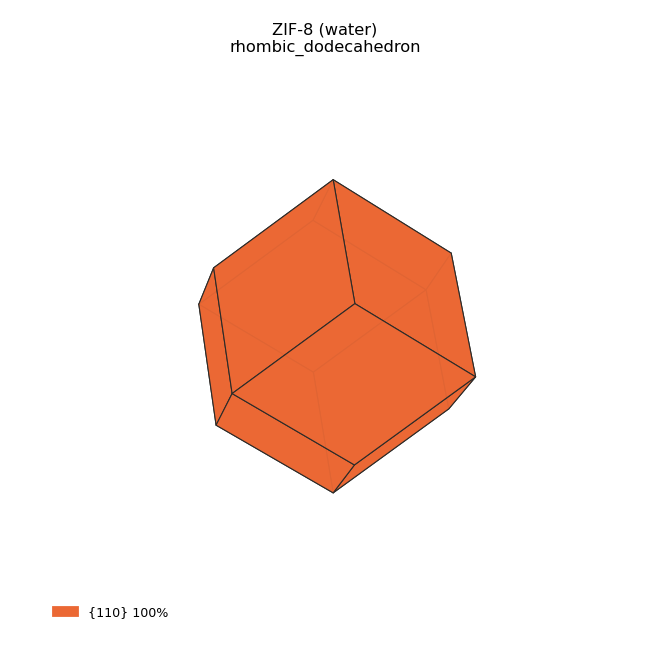

10:25:33 HKUST-1: CuH2(C3O2)2  SG Fm-3m (full)  conv 624 / working 156 atoms
10:25:33    step2 blocks: {'linker:H3C9O6': 8, 'node:Cu2': 6} 
10:25:33    step3 families: {100}(d=26.3), {110}(d=18.6), {111}(d=15.2)
10:25:35    step6 bulk: -7.2997 eV/atom, converged True
10:25:36    {100}: 3 distinct terminations, kept 3
10:25:39       NOT converged: {100} t0 water fmax 0.093
10:25:40       {100} t0 water: 534 atoms, gamma static 0.596, relaxed 0.230 (802 steps)
10:25:41       {100} t1 water: 540 atoms, gamma static 0.646, relaxed 0.228 (773 steps)
10:25:41       {100} t2 water: 552 atoms, gamma static 0.770
10:25:42    {110}: 2 distinct terminations, kept 2
10:25:44       NOT converged: {110} t0 water fmax 0.102
10:25:45       {110} t0 water: 696 atoms, gamma static 1.064, relaxed 0.215 (802 steps)
10:25:46       {110} t1 water: 720 atoms, gamma static 1.258, relaxed 0.264 (707 steps)
10:25:47    {111}: 3 distinct terminations, kept 3
10:25:51       {111} t0 water: 696 atoms, gamma static

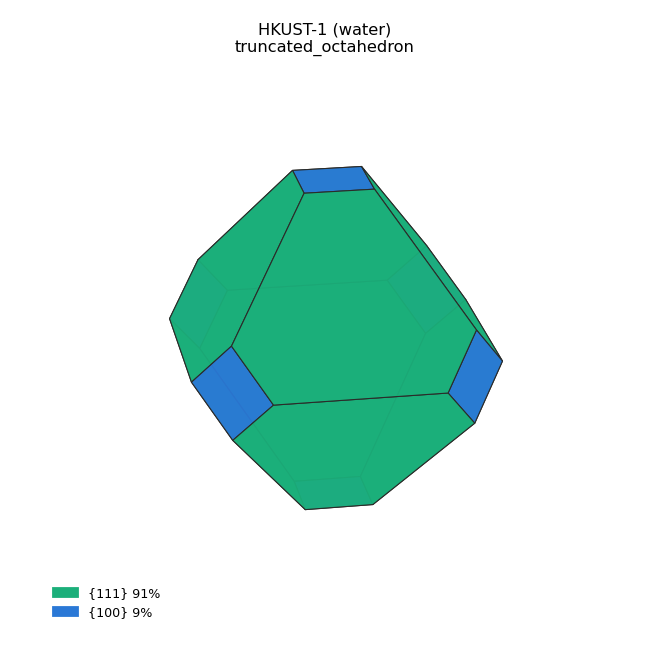

10:25:55 Mg-MOF-74: MgHC4O3  SG R-3 (full)  conv 162 / working 54 atoms
10:25:55    step2 blocks: {'linker:H2C8O6': 3, 'node:Mg1': 6} 
10:25:55    step3 families: {100}(d=22.6), {2̅10}(d=13.1), {001}(d=6.9), {101}(d=6.6)
10:25:57    step6 bulk: -7.5020 eV/atom, converged True
10:25:57    {100}: 3 distinct terminations, kept 3
10:26:00       {100} t1 water: 195 atoms, gamma static 3.137, relaxed 0.121 (572 steps)
10:26:02       {100} t2 water: 201 atoms, gamma static 3.228, relaxed 0.228 (540 steps)
10:26:02       {100} t0 water: 192 atoms, gamma static 3.282
10:26:02    {2̅10}: 4 distinct terminations, kept 4
10:26:07       {2̅10} t1 water: 378 atoms, gamma static 1.216, relaxed -0.013 (191 steps)
10:26:08       {2̅10} t2 water: 387 atoms, gamma static 1.452, relaxed 0.281 (232 steps)
10:26:08       {2̅10} t0 water: 369 atoms, gamma static 2.511
10:26:09       {2̅10} t3 water: 414 atoms, gamma static 3.270
10:26:09    {001}: 2 distinct terminations, kept 2
10:26:12       {001} t0 water

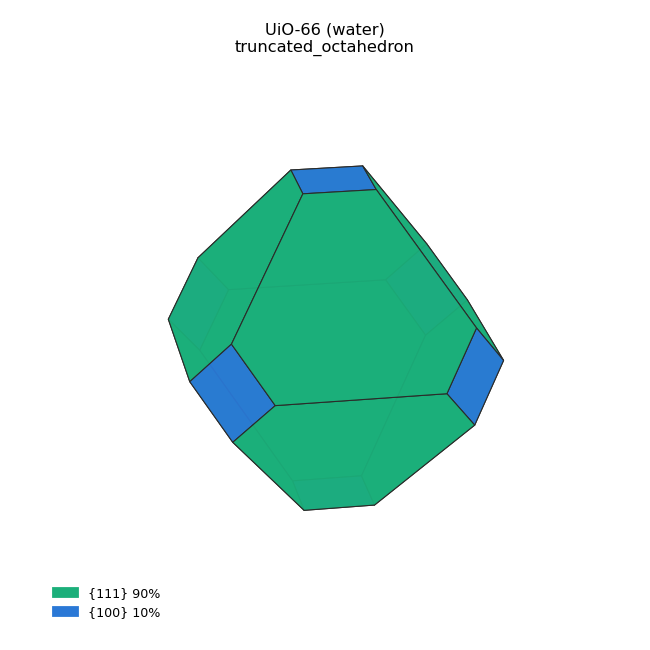

,mof,cap,habit,dominant_face,area_fractions,reference_habit,gamma_source,bulk_converged,n_unconverged,n_rejected,gamma_source,gamma_100,gamma_110,gamma_111,gamma_2m10,gamma_001,gamma_101
0,ZIF-8,water,rhombic_dodecahedron,{110},"{""{110}"": 1.0}",rhombic dodecahedron {110},relaxed,True,0,0,relaxed,0.0197,0.0118,0.0162,NaN,NaN,NaN
1,HKUST-1,water,truncated_octahedron,{111},"{""{111}"": 0.906, ""{100}"": 0.094}",octahedron {111},relaxed,True,2,0,relaxed,0.2279,0.2639,0.1698,NaN,NaN,NaN
2,Mg-MOF-74,water,undefined: gamma <= 0 for {2̅10} (exothermic s...,NaN,NaN,hexagonal rods/needles along c,relaxed,True,1,0,relaxed,0.1208,NaN,NaN,-0.0135,0.0965,0.093
3,UiO-66,water,truncated_octahedron,{111},"{""{111}"": 0.9, ""{100}"": 0.1}",octahedron {111},relaxed,True,0,0,relaxed,0.2674,0.2997,0.2011,NaN,NaN,NaN


In [9]:
# 5. Steps 1-6 and 8
import sys, importlib, json, re
sys.path.insert(0, "/content")
import mofwulff as mw; importlib.reload(mw)
from IPython.display import Image, display

eng = mw.Engine()
only = {x.strip() for x in ONLY.split(",") if x.strip()}
cfg = dict(symprec=SYMPREC, disorder=DISORDER, max_index=MAX_INDEX, n_families=N_FAMILIES,
           thickness=THICKNESS, vacuum=VACUUM, max_terms=MAX_TERMS, cap=CAP,
           relax_steps=0 if QUICK_TEST else RELAX_STEPS, fmax=FMAX, relax_top_k=RELAX_TOP_K)
modes = ["bare", "water"] if CAP == "both" else [CAP if CAP == "water" else "bare"]
ALL, SUMMARY, RUNS = [], [], {}
for _, r in MOFS.iterrows():
    name = r["mof"]
    if only and name not in only or name not in CIF: continue
    faces = None
    if str(r.get("faces", "")).strip():
        faces = [tuple(int(d) for d in re.findall(r"-?\d", t)) for t in re.split(r"[;,\s]+", r["faces"].strip()) if t]
    try:
        meta, fams, recs, bulk = mw.run_mof(eng, name, CIF[name], OUT_DIR, faces=faces, **cfg)
    except Exception as e:
        print(f"{name}: FAILED {type(e).__name__}: {e}"); continue
    RUNS[name] = (meta, fams, recs, bulk); ALL += recs
    for mode in modes:
        row, w = mw.wulff_report(meta, fams, recs, OUT_DIR, mode, need_relaxed=not QUICK_TEST)
        row.update(reference_habit=r.get("reference_habit", ""), bulk_converged=bulk["converged"],
                   n_unconverged=sum(1 for x in recs if x.get("cap") == mode and x.get("converged") is False),
                   n_rejected=sum(1 for x in recs if x.get("cap") == mode and str(x.get("status", "")).startswith("rejected")),
                   notes="; ".join(meta["notes"]))
        if not bulk["converged"]: row["habit"] += "  [WARNING: bulk not converged]"
        SUMMARY.append(row)
        if row.get("png"): display(Image(row["png"]))
slabs = pd.DataFrame(ALL); slabs.to_csv(f"{OUT_DIR}/slabs.csv", index=False)
summary = pd.DataFrame(SUMMARY); summary.to_csv(f"{OUT_DIR}/wulff_summary.csv", index=False)
gcols = [c for c in summary.columns if c.startswith("gamma_")]
display(summary[["mof", "cap", "habit", "dominant_face", "area_fractions", "reference_habit", "gamma_source",
                 "bulk_converged", "n_unconverged", "n_rejected"] + gcols])

In [10]:
# 6. Surface-energy table (every termination). gamma in J/m^2.
cols = ["mof", "face", "termination", "cap", "status", "n_atoms", "n_water", "bonds_per_A2",
        "gamma_static_J_m2", "gamma_relaxed_J_m2", "steps", "final_fmax", "converged", "cuts_infinite_unit"]
display(slabs[[c for c in cols if c in slabs.columns]].sort_values(["mof", "cap", "face", "termination"]))

,mof,face,termination,cap,status,n_atoms,n_water,bonds_per_A2,gamma_static_J_m2,gamma_relaxed_J_m2,steps,final_fmax,converged,cuts_infinite_unit
8,HKUST-1,{100},0,water,healed,534,22,0.02588,0.5959,0.2301,802.0,0.0931,False,False
9,HKUST-1,{100},1,water,healed,540,24,0.02824,0.6465,0.2279,773.0,0.0498,True,False
10,HKUST-1,{100},2,water,healed,552,28,0.03294,0.7697,NaN,NaN,NaN,NaN,False
11,HKUST-1,{110},0,water,healed,696,24,0.02445,1.0639,0.2152,802.0,0.1025,False,False
12,HKUST-1,{110},1,water,healed,720,32,0.03261,1.2583,0.2639,707.0,0.0498,True,False
13,HKUST-1,{111},0,water,healed,696,24,0.01997,0.8591,0.1698,788.0,0.0500,True,False
15,HKUST-1,{111},1,water,healed,768,48,0.03993,1.3756,NaN,NaN,NaN,NaN,False
14,HKUST-1,{111},2,water,healed,768,48,0.03993,1.3556,0.3232,455.0,0.0493,True,False
23,Mg-MOF-74,{001},0,water,healed,558,24,0.04057,0.8590,0.0965,524.0,0.0475,True,False
24,Mg-MOF-74,{001},1,water,healed,567,27,0.04564,1.6660,0.4221,802.0,5.8759,False,False


## Step 7: validation

**7a.** MACE-MP-0, a second universal MLIP trained independently of CHGNet, re-computes the energies of the CHGNet-relaxed bulk, water and slabs (single points). Reported per MOF: Spearman rank correlation of the face ordering, plus MAE in γ. Disagreement flags faces whose CHGNet energies should not be trusted. Agreement does **not** prove accuracy: both models share Materials Project training data.

**7b.** CP2K inputs (PBE-D3(BJ), DZVP-MOLOPT-SR, GTH, 500 Ry) for a small held-out set: the lowest-γ termination of the `VAL_FACES` smallest faces of each of the first `VAL_MOFS` MOFs, plus bulk and H₂O. Run them on an HPC cluster.

**7c.** Upload the DFT energies to get the validation table.

In [11]:
# 7a. Independent-MLIP cross-check (MACE-MP-0)
RUN_MACE = True  #@param {type:"boolean"}
from scipy.stats import spearmanr
import numpy as np
from pymatgen.core import Structure
VAL7A = None
if RUN_MACE and len(slabs):
    if importlib.util.find_spec("mace") is None:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", "mace-torch"], check=True)
    from mace.calculators import mace_mp
    from pymatgen.io.ase import AseAtomsAdaptor
    from ase.build import molecule
    from ase.optimize import BFGS
    calc = mace_mp(model="medium", default_dtype="float64", device="cuda" if torch.cuda.is_available() else "cpu")
    def E(st):
        a = AseAtomsAdaptor.get_atoms(st); a.calc = calc; return float(a.get_potential_energy())
    h2o = molecule("H2O"); h2o.center(vacuum=7.5); h2o.calc = calc; BFGS(h2o, logfile=None).run(fmax=0.02)
    e_w_mace = float(h2o.get_potential_energy())
    rows = []
    for name, (meta, fams, recs, bulk) in RUNS.items():
        b = Structure.from_file(bulk["cif"]); eb = E(b) / len(b)
        for x in recs:
            cif = x.get("relaxed_cif") if x.get("converged") else (x.get("unrelaxed_cif") if QUICK_TEST else None)
            if not cif: continue
            g_chg = x["gamma_relaxed_J_m2"] if x.get("converged") else x["gamma_static_J_m2"]
            st = Structure.from_file(cif)
            g_m = mw.gamma_J_m2(E(st), x["n_slab_atoms"], eb, x["n_water"], e_w_mace, x["area_A2"])
            rows.append(dict(mof=name, face=x["face"], termination=x["termination"], cap=x["cap"],
                             gamma_chgnet=g_chg, gamma_mace=round(g_m, 4)))
    VAL7A = pd.DataFrame(rows)
    if len(VAL7A):
        VAL7A.to_csv(f"{OUT_DIR}/validation_mace.csv", index=False)
        stats = []
        for (m, cap), g in VAL7A.groupby(["mof", "cap"]):
            best = g.loc[g.groupby("face")["gamma_chgnet"].idxmin()]
            rho = spearmanr(best["gamma_chgnet"], best["gamma_mace"]).correlation if len(best) > 2 else np.nan
            same_min = best.loc[best["gamma_chgnet"].idxmin(), "face"] == best.loc[best["gamma_mace"].idxmin(), "face"]
            stats.append(dict(mof=m, cap=cap, n_faces=len(best), spearman_faces=rho, lowest_face_agrees=same_min,
                              MAE_J_m2=float(np.mean(np.abs(g["gamma_chgnet"] - g["gamma_mace"])))))
        display(VAL7A); display(pd.DataFrame(stats))

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Downloading: 100.0% (42.4 MB / 42.4 MB)
Cached MACE model to /root/.cache/mace/20231203mace128L1_epoch199model
Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


,mof,face,termination,cap,gamma_chgnet,gamma_mace
0,ZIF-8,{100},0,water,0.0197,0.0499
1,ZIF-8,{100},1,water,0.0317,0.0605
2,ZIF-8,{110},0,water,0.0118,0.0345
3,ZIF-8,{110},2,water,0.0219,0.0579
4,ZIF-8,{111},0,water,0.0162,0.0380
5,HKUST-1,{100},1,water,0.2279,0.2336
6,HKUST-1,{110},1,water,0.2639,0.2864
7,HKUST-1,{111},0,water,0.1698,0.1707
8,HKUST-1,{111},2,water,0.3232,0.3526
9,Mg-MOF-74,{100},1,water,0.1208,0.1696


,mof,cap,n_faces,spearman_faces,lowest_face_agrees,MAE_J_m2
0,HKUST-1,water,3,1.0,True,0.014625
1,Mg-MOF-74,water,4,1.0,True,0.054843
2,UiO-66,water,3,1.0,True,0.030833
3,ZIF-8,water,3,1.0,True,0.027900


In [12]:
# 7b. CP2K PBE-D3 inputs for a small held-out set
VAL_MOFS  = 2  #@param {type:"integer"}
VAL_FACES = 2  #@param {type:"integer"}
dft_dir = f"{OUT_DIR}/dft_inputs"; os.makedirs(dft_dir, exist_ok=True)
manifest = []
for name, (meta, fams, recs, bulk) in list(RUNS.items())[:VAL_MOFS]:
    tag = re.sub(r"[^\w.-]", "_", name)
    b = Structure.from_file(bulk["cif"])
    open(f"{dft_dir}/{tag}_bulk.inp", "w").write(mw.cp2k_input(b, f"{tag}_bulk"))
    manifest.append(dict(file=f"{tag}_bulk.inp", mof=name, kind="bulk", n_atoms=len(b)))
    ok = [x for x in recs if x.get("relaxed_cif") or (QUICK_TEST and x.get("unrelaxed_cif"))]
    best = {}
    for x in ok:
        g = x.get("gamma_relaxed_J_m2", x.get("gamma_static_J_m2"))
        if x["face"] not in best or g < best[x["face"]][0]: best[x["face"]] = (g, x)
    for face, (g, x) in sorted(best.items(), key=lambda kv: kv[1][1]["n_atoms"])[:VAL_FACES]:
        st = Structure.from_file(x.get("relaxed_cif") or x["unrelaxed_cif"])
        f = f"{tag}_{x['family']}_t{x['termination']}_{x['cap']}.inp"
        open(f"{dft_dir}/{f}", "w").write(mw.cp2k_input(st, f[:-4]))
        manifest.append(dict(file=f, mof=name, kind="slab", face=x["face"], termination=x["termination"], cap=x["cap"],
                             n_atoms=len(st), n_slab_atoms=x["n_slab_atoms"], n_water=x["n_water"], area_A2=x["area_A2"],
                             gamma_chgnet=g))
from pymatgen.core import Molecule
w = Molecule(["O", "H", "H"], [[0, 0, 0], [0.757, 0.586, 0], [-0.757, 0.586, 0]]).get_boxed_structure(15, 15, 15)
open(f"{dft_dir}/H2O.inp", "w").write(mw.cp2k_input(w, "H2O")); manifest.append(dict(file="H2O.inp", kind="water", n_atoms=3))
MANIFEST = pd.DataFrame(manifest); MANIFEST.to_csv(f"{dft_dir}/manifest.csv", index=False); display(MANIFEST)
print("Run each .inp with CP2K (cp2k.psmp -i X.inp). Optimise H2O.inp's geometry or use a single point.")

,file,mof,kind,n_atoms,face,termination,cap,n_slab_atoms,n_water,area_A2,gamma_chgnet
0,ZIF-8_bulk.inp,ZIF-8,bulk,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ZIF-8_100_t0_water.inp,ZIF-8,slab,288,{100},0.0,water,276.0,4.0,288.69,0.0197
2,ZIF-8_110_t0_water.inp,ZIF-8,slab,564,{110},0.0,water,552.0,4.0,408.28,0.0118
3,HKUST-1_bulk.inp,HKUST-1,bulk,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,HKUST-1_100_t1_water.inp,HKUST-1,slab,540,{100},1.0,water,468.0,24.0,849.92,0.2279
5,HKUST-1_110_t0_water.inp,HKUST-1,slab,696,{110},0.0,water,624.0,24.0,981.40,0.2152
6,H2O.inp,NaN,water,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Run each .inp with CP2K (cp2k.psmp -i X.inp). Optimise H2O.inp's geometry or use a single point.


In [13]:
# 7c. Upload DFT results: CSV with columns  file, energy  (energy in Hartree, as CP2K prints; or add column unit=eV)
UPLOAD_DFT = False  #@param {type:"boolean"}
if UPLOAD_DFT:
    from google.colab import files
    up = files.upload(); dft = pd.read_csv(list(up)[0])
    is_ev = dft["unit"].astype(str).str.lower().eq("ev") if "unit" in dft else False
    dft["E_eV"] = np.where(is_ev, dft["energy"], dft["energy"] * 27.211386)
    m = MANIFEST.merge(dft[["file", "E_eV"]], on="file", how="left")
    ew = m.loc[m["kind"] == "water", "E_eV"].iloc[0]
    out = []
    for name, g in m.groupby("mof"):
        b = g[g["kind"] == "bulk"].iloc[0]; eb = b["E_eV"] / b["n_atoms"]
        for _, s in g[g["kind"] == "slab"].iterrows():
            gd = mw.gamma_J_m2(s["E_eV"], s["n_slab_atoms"], eb, s["n_water"], ew, s["area_A2"]) if pd.notna(s["E_eV"]) else np.nan
            out.append(dict(mof=name, face=s["face"], cap=s["cap"], gamma_chgnet=s["gamma_chgnet"], gamma_dft=gd,
                            status="failed/missing" if np.isnan(gd) else "ok"))
    V = pd.DataFrame(out); V.to_csv(f"{OUT_DIR}/validation_dft.csv", index=False); display(V)
    okv = V.dropna()
    if len(okv) > 2:
        print("MAE (J/m2):", float(np.mean(np.abs(okv.gamma_chgnet - okv.gamma_dft))),
              "| Spearman:", spearmanr(okv.gamma_chgnet, okv.gamma_dft).correlation,
              "| failures:", int(V.gamma_dft.isna().sum()))

In [14]:
# 8. Download everything (CSVs, Wulff PNG/OBJ, relaxed slab CIFs, DFT inputs)
import shutil
shutil.make_archive("/content/mof_wulff_results", "zip", OUT_DIR)
try:
    from google.colab import files; files.download("/content/mof_wulff_results.zip")
except Exception:
    print("zip at /content/mof_wulff_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limits that remain (steps 1–8)
- γ is the **average of the two faces** for slabs whose top and bottom terminations differ (`symmetric` is not enforced). For non-centrosymmetric MOFs (ZIF-8, I-43m) {111} and {1̅1̅1̅} are always averaged.
- The healing chemistry is one choice (dissociated water). Other caps (formate, DMF, modulator acid) change γ. That dependence on conditions is what steps 9–10 model.
- Static screening picks which terminations to relax. A termination ranked high statically but low after relaxation can be missed; raise `RELAX_TOP_K` to check.
- CHGNet is not validated for MOF surfaces. Treat habits as hypotheses until 7c is done.

# GNN surrogate for surface energies (option a)

**Role.** A fast student of the expensive teacher. The teacher is steps 4–6: build the slab, heal it, relax it with CHGNet, compute γ. The student is a graph neural network that reads the **unrelaxed healed slab** and predicts γ directly. Step 8 is unchanged: lowest γ per face family → Wulff → habit.

| | |
|---|---|
| Input | atom graph of the healed slab: nodes = atoms (element, metal / cap / donor flags, bond counts, depth below the surface), edges = the pipeline's own bond rules (org, M–M, M–ligand, M–oxo) with distance features |
| Output | γ per (face, termination), in J/m² |
| Readout | each atom gets an excess energy eᵢ; γ = Σeᵢ / 2A. Same form as γ = (E_slab − N·e_bulk − n·E_H₂O)/2A, so it does not depend on slab thickness |
| Labels | `gamma_relaxed_J_m2` from step 6 (converged slabs only) |
| Split | by MOF: leave-one-MOF-out up to 10 MOFs, grouped 5-fold above that |
| Baselines (every fold) | constant mean · linear fit on broken bonds per Å² · CHGNet static γ (raw and linearly calibrated) |

**Why the input is the unrelaxed slab.** Relaxation is the step the GNN is supposed to skip. A model trained on relaxed geometries would need a CHGNet relaxation before it could be used.

**`TARGET = "delta"`** learns γ_relaxed − γ_static instead. Each new slab then needs one CHGNet single point (seconds) but no relaxation. Try both. The GNN must beat the static-CHGNet baseline to be worth having, because that baseline already costs only seconds.

**Version 2 fixes (after the MIL-101 and CALF-20-Cl tests):**
- *Surface cutoff.* Each atom's energy is multiplied by a weight that is 1 at the surface and 0 deeper than 12 Å, so bulk atoms add nothing. Before this, γ grew with slab thickness: the same ZIF-8 surface gave 0.74, 1.31 and 2.16 J/m² for 30, 60 and 90 Å slabs, and MIL-101's 14,700-atom slabs all came out near −0.45.
- *γ > 0.* The output passes through a softplus, because a Wulff shape needs positive γ on every face.
- *BFDH from the project note.* d_eff = d/n, where n is the first order whose structure factor is not cancelled. It is used as a baseline in cell 11 and printed next to every GNN prediction in cell 13. It reproduces the note's worked numbers: MOF-5 truncated octahedron 77.6 % {111}; Mg-MOF-74 rod, {2̅10} 77.4 %.
- *Out-of-range warning.* Cell 13 lists elements the GNN never saw in training, and flags slabs far larger than any training slab.
- *Shape names* in `mofwulff.name_habit` now follow the note: cube → truncated cube → cuboctahedron (exactly 63.4 % {100}) → truncated octahedron → octahedron, and Zingg 2/3 ratios for rod / plate / lath. Before, a truncated octahedron with more than 20 % {100} was called a cuboctahedron.

**Labels for every termination.** The main run relaxes only the `RELAX_TOP_K = 2` lowest static terminations per face. A GNN trained on those never sees relaxed values for higher-energy terminations, yet it has to rank all of them at inference. For training data, set `RELAX_TOP_K_TRAIN = MAX_TERMS` (cell 9). This costs about 4× more GPU time per MOF.

In [15]:
%%writefile /content/mofgnn.py
"""GNN surrogate for MOF slab surface energies (option a: structure graph -> gamma).

Teacher : steps 1-6 of mofwulff (healed slab + CHGNet relaxation) -> gamma_relaxed per (MOF, face, termination)
Student : a message-passing GNN on the atom graph of the *unrelaxed* healed slab -> gamma
Then    : lowest predicted gamma per face family -> mofwulff.wulff -> habit (unchanged step 8)

Design rules (each one is a choice, documented here so it can be defended):
  * Input geometry = UNRELAXED healed slab (steps 1-5 only). Relaxation is the expensive step the
    student is meant to skip, so it cannot be an input at inference. Training on relaxed CIFs would
    give a model that needs CHGNet relaxation before it can be used.
  * Edges = the pipeline's own bond rules (mofwulff.bond_kind: org / MM / ML / MO), periodic in-plane.
  * Readout is physical: each atom gets an excess energy e_i (eV); gamma = sum(e_i) / (2A).
    This mirrors gamma = (E_slab - N e_bulk - n E_H2O) / 2A, so the model is size-consistent
    (thicker slab or bigger surface cell -> same gamma).
  * Split by MOF (leave-one-MOF-out, or grouped k-fold for >10 MOFs). A MOF in the test fold never
    appears in training.
  * Baselines are run in every fold: constant mean, linear fit on broken bonds per area, and (when the
    label is relaxed gamma) CHGNet static gamma. The GNN is only useful if it beats them.
  * Surface-localised readout: e_i is multiplied by a smooth cutoff w(depth) that is 1 at the surface
    and 0 deeper than DEPTH_MAX. Atoms deep inside the slab are bulk, so they must add nothing; without
    this, a small per-atom bias adds up in thick slabs (MIL-101: 14,700-atom slabs -> gamma -0.45).
  * positive=True (default for target="gamma") makes gamma = softplus(raw): a crystal with a Wulff shape
    needs gamma > 0 on every face.
  * BFDH (geometry only, project note "CIF to Shape"): d_eff = d_hkl / n, n = first order whose
    structure factor is not cancelled; growth distance proportional to 1/d_eff. Used as a baseline in
    cross-validation and as a cross-check printed next to every GNN prediction.
  * target="delta" learns gamma_relaxed - gamma_static instead (needs one CHGNet single point per slab
    at inference, seconds on a GPU). target="gamma" needs no CHGNet at all.
"""
import json, math, re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pymatgen.core import Element, Lattice, Structure
from scipy.stats import spearmanr

import mofwulff as mw

EV_A2_TO_J_M2 = mw.EV_A2_TO_J_M2
EDGE_KINDS = ["org", "MM", "ML", "MO"]
N_RBF = 16
RBF_MU = np.linspace(0.8, mw.OUT_REACH, N_RBF)
DEPTH_MAX = 12.0                       # A; atoms deeper than this are treated as bulk-like
NODE_FLOAT = 4 + len(EDGE_KINDS) + 2   # is_metal, is_cap, is_donor, is_lig_donor, bond counts, depth, exp(-depth/2)


# ============================================================================ graph building
def slab_graph(st, n_slab_atoms, area_A2):
    """Atom graph of one healed slab.

    Nodes: atomic number (embedded) + float features
           [is_metal, is_cap (atom added by healing), is_donor, is_ligand_donor,
            bond counts per kind (org, MM, ML, MO), depth below nearest surface / DEPTH_MAX, exp(-depth/2)].
    Edges: every pair the pipeline calls a bond, both directions; features = kind one-hot + distance RBF.
    The slab normal is the c axis (block_slabs builds c = n * (thickness + vacuum)); healing appends
    cap atoms after the n_slab_atoms framework atoms, so index >= n_slab_atoms marks a cap atom.
    """
    nbs = st.get_all_neighbors(mw.OUT_REACH)
    lig = mw.ligand_donors(st, nbs)
    sym = [x.specie.symbol for x in st]
    src, dst, kind, dist = [], [], [], []
    counts = np.zeros((len(st), len(EDGE_KINDS)))
    for i in range(len(st)):
        for n in nbs[i]:
            k = mw.bond_kind(sym[i], sym[n.index], n.nn_distance, i in lig, n.index in lig)
            if k:
                src.append(n.index); dst.append(i); kind.append(EDGE_KINDS.index(k)); dist.append(n.nn_distance)
                counts[i, EDGE_KINDS.index(k)] += 1
    chat = st.lattice.matrix[2] / np.linalg.norm(st.lattice.matrix[2])
    z = st.cart_coords @ chat
    frame = z[:n_slab_atoms]
    depth = np.clip(np.minimum(z - frame.min(), frame.max() - z), 0, DEPTH_MAX)
    is_cap = np.arange(len(st)) >= n_slab_atoms
    x = np.c_[[mw.is_metal(s) for s in sym], is_cap, [s in mw.DONORS for s in sym],
              [i in lig for i in range(len(st))], counts, depth / DEPTH_MAX, np.exp(-depth / 2)].astype(np.float32)
    d = np.array(dist)
    ea = np.c_[np.eye(len(EDGE_KINDS))[kind], np.exp(-((d[:, None] - RBF_MU) / 0.15) ** 2)].astype(np.float32)
    return dict(z=torch.tensor([Element(s).Z for s in sym], dtype=torch.long), x=torch.from_numpy(x),
                edge_index=torch.tensor([src, dst], dtype=torch.long), edge_attr=torch.from_numpy(ea),
                area=float(area_A2), n_atoms=len(st))


def read_cif_in_order(path):
    """Read a pipeline CIF with the original site order.

    pymatgen writes sites in order but its CIF parser regroups them by element, so the healing caps
    (appended last) no longer sit at index >= n_slab_atoms. The writer's labels carry the original
    index (O0, H1, C2, ...), so the order is restored from them."""
    st = Structure.from_file(path)
    num = [re.search(r"(\d+)$", str(s.label or "")) for s in st]
    if all(num) and len({int(n.group(1)) for n in num}) == len(st):
        order = np.argsort([int(n.group(1)) for n in num])
        st = Structure.from_sites([st[int(i)] for i in order])
    return st


def _resolve(path, out_dir):
    """slabs.csv stores absolute Colab paths; re-root them under out_dir if the results moved."""
    if isinstance(path, str) and Path(path).exists():
        return path
    if not isinstance(path, str) or "structures/" not in path:
        return None
    p = Path(out_dir) / ("structures/" + path.split("structures/", 1)[1])
    return str(p) if p.exists() else None


def export_graphs(out_dir, slabs_csv=None, cap="water", source="unrelaxed"):
    """Turn every healed slab of slabs.csv into a graph file (out_dir/graphs/*.pt) + index.csv.

    One row per slab with graph path and all labels (gamma_static_J_m2, gamma_relaxed_J_m2, converged).
    source="unrelaxed" (default, see module docstring) or "relaxed" (only for analysis).
    """
    out_dir = Path(out_dir)
    df = pd.read_csv(slabs_csv or out_dir / "slabs.csv")
    for c in ("gamma_relaxed_J_m2", "converged", "unrelaxed_cif", "relaxed_cif"):
        if c not in df:
            df[c] = np.nan                     # static-only runs (QUICK_TEST) have no relaxation columns
    df = df[(df["cap"] == cap) & df["gamma_static_J_m2"].notna()].copy()
    gdir = out_dir / "graphs"; gdir.mkdir(exist_ok=True)
    rows, skipped = [], Counter()
    for _, r in df.iterrows():
        cif = _resolve(r.get("unrelaxed_cif" if source == "unrelaxed" else "relaxed_cif"), out_dir)
        if cif is None:
            skipped["missing cif"] += 1; continue
        p = gdir / (Path(cif).stem + ".pt")
        if not p.exists():
            st = read_cif_in_order(cif)
            n_slab = int(r["n_slab_atoms"])
            if len(st) != int(r["n_atoms"]):
                skipped["atom count mismatch"] += 1; continue
            if not {s.specie.symbol for s in st[n_slab:]} <= {"O", "H"}:
                skipped["cap atoms not O/H (site order lost)"] += 1; continue
            torch.save(slab_graph(st, n_slab, r["area_A2"]), p)
        rows.append({**r.to_dict(), "graph": str(p)})
    idx = pd.DataFrame(rows)
    idx.to_csv(gdir / "index.csv", index=False)
    print(f"{len(idx)} graphs from {idx['mof'].nunique() if len(idx) else 0} MOFs -> {gdir}"
          + (f" | skipped {dict(skipped)}" if skipped else ""))
    return idx


# ============================================================================ model
class GatedConv(nn.Module):
    """CGCNN-style gated message passing with a residual update."""
    def __init__(self, h, e):
        super().__init__()
        self.lin = nn.Linear(2 * h + e, 2 * h)
        self.norm = nn.LayerNorm(h)

    def forward(self, x, ei, ea):
        s, d = ei
        gate, core = self.lin(torch.cat([x[d], x[s], ea], -1)).chunk(2, -1)
        msg = torch.sigmoid(gate) * F.softplus(core)
        agg = torch.zeros_like(x).index_add_(0, d, msg)
        return F.softplus(x + self.norm(agg))


def surface_weight(depth):
    """1 at the surface, 0 deeper than DEPTH_MAX (cosine cutoff)."""
    return 0.5 * (1 + torch.cos(math.pi * torch.clamp(depth, max=DEPTH_MAX) / DEPTH_MAX))


class SlabGNN(nn.Module):
    """Atom graph -> per-atom excess energy (eV) x surface weight -> gamma = sum / 2A (J/m^2)."""
    def __init__(self, hidden=64, layers=4, max_z=100, positive=True):
        super().__init__()
        self.positive = positive
        self.emb = nn.Embedding(max_z + 1, hidden)
        self.inp = nn.Linear(NODE_FLOAT, hidden)
        e_dim = len(EDGE_KINDS) + N_RBF
        self.convs = nn.ModuleList([GatedConv(hidden, e_dim) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.Softplus(), nn.Linear(hidden, 1))

    def forward(self, b):
        x = self.emb(b["z"]) + self.inp(b["x"])
        for c in self.convs:
            x = c(x, b["edge_index"], b["edge_attr"])
        e_atom = self.head(x).squeeze(-1) * surface_weight(b["x"][:, 8] * DEPTH_MAX)
        e_slab = torch.zeros(b["n_graphs"], device=x.device).index_add_(0, b["batch"], e_atom)
        g = e_slab / (2 * b["area"]) * EV_A2_TO_J_M2
        return F.softplus(g) if self.positive else g      # beta=1: no dead zone for negative raw values


def collate(graphs, device):
    zs, xs, eis, eas, batch, off = [], [], [], [], [], 0
    for i, g in enumerate(graphs):
        zs.append(g["z"]); xs.append(g["x"]); eas.append(g["edge_attr"]); eis.append(g["edge_index"] + off)
        batch.append(torch.full((g["n_atoms"],), i, dtype=torch.long)); off += g["n_atoms"]
    return dict(z=torch.cat(zs).to(device), x=torch.cat(xs).to(device), edge_index=torch.cat(eis, 1).to(device),
                edge_attr=torch.cat(eas).to(device), batch=torch.cat(batch).to(device), n_graphs=len(graphs),
                area=torch.tensor([g["area"] for g in graphs], dtype=torch.float32, device=device))


# ============================================================================ data
def load_dataset(index, label="gamma_relaxed_J_m2", target="gamma", require_converged=True):
    """Labelled rows of index.csv + their graphs.

    label  : column used as truth. gamma_relaxed_J_m2 for real runs. gamma_static_J_m2 only for
             smoke tests (the pipeline relaxes just RELAX_TOP_K terminations per family).
    target : "gamma" -> model predicts the label; "delta" -> model predicts label - gamma_static.
    Returns (labelled DataFrame, {graph path: graph}) ; unlabelled rows stay in `index` for inference.
    """
    idx = index if isinstance(index, pd.DataFrame) else pd.read_csv(index)
    lab = idx[idx[label].notna()].copy()
    if require_converged and label == "gamma_relaxed_J_m2" and "converged" in lab:
        lab = lab[lab["converged"].astype(str).str.lower() == "true"]
    lab["y"] = lab[label] - (lab["gamma_static_J_m2"] if target == "delta" else 0.0)
    graphs = {p: torch.load(p, weights_only=False) for p in idx["graph"]}
    return lab.reset_index(drop=True), graphs


def _mof_batches(df, batch_size, rng):
    """Batches that keep a MOF's slabs together, so the ranking loss sees within-MOF pairs."""
    groups = [g.index.to_numpy() for _, g in df.groupby("mof")]
    rng.shuffle(groups)
    cur = []
    for g in groups:
        g = rng.permutation(g)
        for i in range(0, len(g), batch_size):
            cur.extend(g[i:i + batch_size].tolist())
            if len(cur) >= batch_size:
                yield cur; cur = []
    if cur:
        yield cur


def _rank_loss(pred, y, mof_ids, tau=0.1, min_gap=0.02):
    """Pairwise logistic loss on within-MOF orderings (the Wulff shape depends on the ordering)."""
    dy = y[:, None] - y[None, :]
    same = (mof_ids[:, None] == mof_ids[None, :]) & (dy.abs() > min_gap)
    if not same.any():
        return pred.sum() * 0
    dp = pred[:, None] - pred[None, :]
    return F.softplus(-torch.sign(dy[same]) * dp[same] / tau).mean()


# ============================================================================ training
def train(df, graphs, epochs=300, hidden=64, layers=4, lr=1e-3, weight_decay=1e-4, batch_size=16,
          rank_weight=0.5, seed=0, device=None, val_df=None, patience=60, verbose=False, positive=True,
          init_state=None):
    """Train one SlabGNN. If val_df is given, keeps the epoch with the lowest validation MAE.
    init_state: weights to start from (fine-tuning after pretraining)."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = SlabGNN(hidden, layers, positive=positive).to(device)
    if init_state is not None:
        model.load_state_dict(init_state)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    mof_code = {m: i for i, m in enumerate(df["mof"].unique())}
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        for ids in _mof_batches(df, batch_size, rng):
            sub = df.loc[ids]
            b = collate([graphs[p] for p in sub["graph"]], device)
            y = torch.tensor(sub["y"].to_numpy(), dtype=torch.float32, device=device)
            m = torch.tensor([mof_code[x] for x in sub["mof"]], device=device)
            pred = model(b)
            loss = F.huber_loss(pred, y, delta=0.3) + rank_weight * _rank_loss(pred, y, m)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        sched.step()
        if val_df is not None and len(val_df):
            mae = float(np.mean(np.abs(predict(model, val_df, graphs, device) - val_df["y"].to_numpy())))
            if mae < best - 1e-4:
                best, bad = mae, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience:
                    break
        if verbose and ep % 50 == 0:
            print(f"epoch {ep} loss {float(loss):.4f}" + (f" val MAE {best:.4f}" if val_df is not None else ""))
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


@torch.no_grad()
def predict(model, df, graphs, device=None, batch_size=32):
    device = device or next(model.parameters()).device
    model.eval(); out = []
    paths = list(df["graph"])
    for i in range(0, len(paths), batch_size):
        out.append(model(collate([graphs[p] for p in paths[i:i + batch_size]], device)).cpu().numpy())
    return np.concatenate(out) if out else np.array([])


def train_ensemble(df, graphs, n_seeds=3, val_mofs=0, init_states=None, **kw):
    """n_seeds models; if val_mofs > 0, that many training MOFs are held out for early stopping.
    init_states: one state dict per seed (from pretrain), or None."""
    models = []
    for s in range(n_seeds):
        if init_states is not None:
            kw = {**kw, "init_state": init_states[s % len(init_states)]}
        tr, va = df, None
        if val_mofs:
            mofs = np.random.default_rng(100 + s).permutation(df["mof"].unique())
            va = df[df["mof"].isin(mofs[:val_mofs])]; tr = df[~df["mof"].isin(mofs[:val_mofs])]
        models.append(train(tr.reset_index(drop=True), graphs, seed=s,
                            val_df=None if va is None else va.reset_index(drop=True), **kw))
    return models


def pretrain_states(index, graphs, exclude_mofs=(), n_seeds=3, epochs=100, **kw):
    """Pretrain on CHGNet *static* gamma (cheap: seconds per MOF) of every slab whose MOF is not excluded.
    Returns one state dict per seed, used as the starting point for fine-tuning on relaxed gamma.
    In cross-validation the test MOFs are excluded, so nothing about them is seen before testing."""
    pre = index[index["gamma_static_J_m2"].notna() & ~index["mof"].isin(list(exclude_mofs))].copy()
    pre["y"] = pre["gamma_static_J_m2"]
    if pre["mof"].nunique() < 2:
        return None
    ms = train_ensemble(pre.reset_index(drop=True), graphs, n_seeds=n_seeds, epochs=epochs,
                        **{k: v for k, v in kw.items() if k not in ("init_state", "epochs")})
    return [{k: v.detach().clone() for k, v in m.state_dict().items()} for m in ms]


def predict_ensemble(models, df, graphs):
    return np.mean([predict(m, df, graphs) for m in models], axis=0)


# ============================================================================ Wulff from any gamma table
def _families_from_meta(meta):
    conv = Structure(Lattice(meta["conv_lattice"]), ["H"], [[0, 0, 0]])
    rots = [np.array(r) for r in meta["_rotations"]]
    fams = mw.face_families(conv, rots, faces=[tuple(f["rep"]) for f in meta["families"]])
    return conv, fams, rots


def habit_from_gammas(meta, gammas):
    """gammas: {family key: gamma}. Returns (habit name, dominant face, wulff dict)."""
    conv, fams, rots = _families_from_meta(meta)
    g = {k: v for k, v in gammas.items() if np.isfinite(v)}
    if len(g) < 2:
        return "not enough faces", None, None
    if min(g.values()) <= 0:
        return "undefined (gamma <= 0)", None, None
    if min(g.values()) < 1e-3:
        return "undefined (gamma ~ 0)", None, None
    try:
        w = mw.wulff(conv, fams, g, rots)
    except Exception as exc:                     # degenerate polyhedron (e.g. qhull on a point)
        return f"undefined (Wulff failed: {type(exc).__name__})", None, None
    if w is None:
        return "no faces", None, None
    name = mw.name_habit(w, fams, meta["crystal_system"], conv)
    names = {f["key"]: f["name"] for f in fams}
    fr = {names.get(k, k): v for k, v in w["area_fractions"].items()}
    return name, max(fr, key=fr.get), w


def habit_class(name):
    """Coarse habit label for agreement checks ('block/prism: {100} 60%, ...' -> 'block/prism')."""
    return re.split(r"[:(]", str(name))[0].strip()


def load_meta(out_dir, mof):
    return json.loads((Path(out_dir) / "cache" / re.sub(r"[^\w.-]", "_", mof) / "meta.json").read_text())


# ============================================================================ BFDH (geometry only)
def structure_factor(st, hkl):
    """|F(hkl)| / sum(Z): Z-weighted sum of exp(2 pi i h.x) over the atoms of st (project note, Step 7)."""
    Z = np.array([x.specie.Z for x in st], float)
    ph = 2 * np.pi * (st.frac_coords @ np.asarray(hkl, float))
    return float(abs(np.sum(Z * np.exp(1j * ph))) / Z.sum())


def _skeleton(info):
    """Atoms used for the cancellation test: the same skeleton that gave the symmetry in step 1.
    H is always left out (ordered H in a CIF breaks symmetry that the framework has)."""
    st = info["conv"].copy()
    els = {x.specie.symbol for x in st}
    if info["symmetry_source"] == "metal+C":
        st.remove_species([e for e in els if not (mw.is_metal(e) or e == "C")])
    elif "H" in els:
        st.remove_species(["H"])
    return st


def d_eff_table(info, families, max_order=8, tol=0.01):
    """d_eff = d_hkl / n for each family; n = first order n*(hkl) whose |F| / sum(Z) > tol.
    Note: rotations make every member of a family equivalent, so the representative is enough."""
    sk = _skeleton(info)
    out = {}
    for f in families:
        h = np.array(f["rep"]); d = float(info["conv"].lattice.d_hkl(tuple(int(x) for x in h)))
        n = next((k for k in range(1, max_order + 1) if structure_factor(sk, k * h) > tol), None)
        out[f["key"]] = dict(name=f["name"], d=round(d, 4), n=n or max_order, d_eff=round(d / (n or max_order), 4),
                             all_orders_cancelled=n is None)
    return out


def bfdh_for_mof(out_dir, mof):
    """d_eff table for a MOF of the pipeline run (cached in cache/<mof>/bfdh.json). None if the CIF is gone."""
    cdir = Path(out_dir) / "cache" / re.sub(r"[^\w.-]", "_", mof)
    if (cdir / "bfdh.json").exists():
        return json.loads((cdir / "bfdh.json").read_text())
    try:
        meta = load_meta(out_dir, mof)
    except FileNotFoundError:
        return None
    if not Path(meta.get("cif", "")).exists():
        return None
    c = meta.get("config", {})
    info = mw.standardize(meta["cif"], c.get("symprec", 0.1), c.get("disorder", "majority"))
    fams = mw.face_families(info["conv"], info["rotations"], faces=[tuple(f["rep"]) for f in meta["families"]])
    t = d_eff_table(info, fams)
    (cdir / "bfdh.json").write_text(json.dumps(t, indent=1))
    return t


def bfdh_habit(meta, table):
    """BFDH shape: Wulff construction with plane distances proportional to 1/d_eff."""
    return habit_from_gammas(meta, {k: 1.0 / v["d_eff"] for k, v in table.items()})


# ============================================================================ saving / loading
def training_elements(lab, graphs):
    return sorted({Element.from_Z(int(z)).symbol for p in lab["graph"] for z in torch.unique(graphs[p]["z"]).tolist()})


def save_models(path, models, lab, graphs, hidden, layers, label, target):
    torch.save(dict(version=2, states=[m.state_dict() for m in models], hidden=hidden, layers=layers,
                    positive=models[0].positive, label=label, target=target,
                    mofs=sorted(lab["mof"].unique()), elements=training_elements(lab, graphs)), path)


def load_models(path, graphs_dir=None, device=None):
    """Returns (models, checkpoint dict). Old checkpoints (before the surface cutoff) are flagged."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(path, weights_only=False, map_location=device)
    if ck.get("version", 1) < 2:
        print("WARNING: this model was trained with the old readout (no surface cutoff, no positivity). "
              "Retrain it (cells 11-12) before trusting predictions.")
    models = []
    for st in ck["states"]:
        m = SlabGNN(ck["hidden"], ck["layers"], positive=ck.get("positive", False)).to(device)
        m.load_state_dict(st); m.eval(); models.append(m)
    if not ck.get("elements") and graphs_dir:
        zs = set()
        for p in Path(graphs_dir).glob("*.pt"):
            zs |= set(torch.load(p, weights_only=False)["z"].tolist())
        ck["elements"] = sorted(Element.from_Z(int(z)).symbol for z in zs)
    return models, ck


# ============================================================================ evaluation
def _family_table(rows, col):
    """Lowest value of `col` per face family."""
    r = rows[rows[col].notna()]
    return r.groupby("family")[col].min().to_dict()


def evaluate_mof(out_dir, mof, test_rows, all_rows, truth_col, pred_cols):
    """Per-MOF metrics for each predictor column.
    truth: lowest labelled gamma per family. prediction: lowest predicted gamma per family over ALL
    terminations (labelled or not), which is how the model is used at inference."""
    meta = load_meta(out_dir, mof)
    true_f = _family_table(test_rows, truth_col)
    true_habit, true_dom, _ = habit_from_gammas(meta, true_f)
    out = []
    for name, col in pred_cols.items():
        if col not in all_rows or all_rows[col].isna().all():
            continue
        pred_f = {k: v for k, v in _family_table(all_rows, col).items() if k in true_f}
        fams = sorted(true_f)
        rho = spearmanr([true_f[k] for k in fams], [pred_f[k] for k in fams]).correlation if len(fams) > 2 else np.nan
        habit, dom, _ = habit_from_gammas(meta, pred_f)
        lab = test_rows[test_rows[col].notna()]
        out.append(dict(mof=mof, model=name, n_labelled=len(lab), n_families=len(fams),
                        MAE_J_m2=float(np.mean(np.abs(lab[col] - lab[truth_col]))),
                        spearman_families=rho,
                        lowest_face_agrees=min(true_f, key=true_f.get) == min(pred_f, key=pred_f.get),
                        true_habit=true_habit, pred_habit=habit,
                        # no Wulff shape exists when the truth has gamma <= 0: not counted as agreement
                        habit_agrees=(habit_class(true_habit) == habit_class(habit)) if true_dom is not None else np.nan,
                        dominant_agrees=(true_dom == dom) if true_dom is not None else np.nan))
    return out


def cross_validate(out_dir, index, label="gamma_relaxed_J_m2", target="gamma", n_folds=None, n_seeds=3,
                   val_mofs=0, pretrain=False, pretrain_epochs=30, pretrain_seeds=1, finetune_lr=3e-4,
                   groups=None, **train_kw):
    """Grouped-by-MOF cross-validation of the GNN against baselines.

    Folds: leave-one-group-out when there are <= 10 groups, otherwise n_folds (default 5) grouped folds.
    groups: {mof: family} so near-copies (Mg/Ni/Zn/Co-MOF-74, the IRMOF series, ...) are always on the
    same side of the split, including during pretraining. MOFs not listed form their own group.
    Returns (per-slab predictions, per-MOF metrics, summary).
    """
    idx = index if isinstance(index, pd.DataFrame) else pd.read_csv(index)
    lab, graphs = load_dataset(idx, label, target)
    mofs = np.array(sorted(lab["mof"].unique()))
    inv_d = {}                                       # (mof, family) -> 1/d_eff, for the BFDH baseline
    for m in idx["mof"].unique():
        t = bfdh_for_mof(out_dir, m)
        if t:
            inv_d.update({(m, k): 1.0 / v["d_eff"] for k, v in t.items()})
    if len(mofs) < 2:
        raise ValueError("need labelled slabs from at least 2 MOFs")
    grp = lambda m: (groups or {}).get(m, m)
    gnames = np.array(sorted({grp(m) for m in mofs}))
    if len(gnames) < 2:
        raise ValueError("need labelled slabs from at least 2 groups")
    k = len(gnames) if (n_folds is None and len(gnames) <= 10) else (n_folds or 5)
    gfolds = np.array_split(np.random.default_rng(0).permutation(gnames), k)
    folds = [np.array([m for m in mofs if grp(m) in set(gf)]) for gf in gfolds]
    all_mofs = idx["mof"].unique()
    preds, metrics = [], []
    for fi, test_mofs in enumerate(folds):
        tr = lab[~lab["mof"].isin(test_mofs)].reset_index(drop=True)
        init = None
        if pretrain:
            test_groups = {grp(m) for m in test_mofs}
            excl = [m for m in all_mofs if grp(m) in test_groups]          # whole test families stay unseen
            init = pretrain_states(idx, graphs, exclude_mofs=excl, n_seeds=pretrain_seeds, epochs=pretrain_epochs,
                                   **{k: v for k, v in train_kw.items() if k in ("hidden", "layers", "batch_size")})
        kw = {"positive": target == "gamma", **train_kw}
        if init is not None:
            kw["lr"] = finetune_lr
        models = train_ensemble(tr, graphs, n_seeds=n_seeds, val_mofs=val_mofs, init_states=init, **kw)
        # baselines fitted on the training MOFs only
        a, b0 = np.polyfit(tr["bonds_per_A2"], tr[label], 1)
        mean_y = tr[label].mean()
        if label != "gamma_static_J_m2":
            s1, s0 = np.polyfit(tr["gamma_static_J_m2"], tr[label], 1)
        trb = tr.assign(inv_d=[inv_d.get((m, f), np.nan) for m, f in zip(tr["mof"], tr["family"])]).dropna(subset=["inv_d"])
        bf = np.polyfit(trb["inv_d"], trb[label], 1) if trb["mof"].nunique() >= 2 else None
        for m in test_mofs:
            all_m = idx[idx["mof"] == m].copy()
            g = predict_ensemble(models, all_m, graphs)
            all_m["pred_gnn"] = g + (all_m["gamma_static_J_m2"].to_numpy() if target == "delta" else 0)
            all_m["pred_mean"] = mean_y
            all_m["pred_bonds_linear"] = a * all_m["bonds_per_A2"] + b0
            if bf is not None:
                iv = np.array([inv_d.get((m, f), np.nan) for f in all_m["family"]])
                if np.isfinite(iv).all():
                    all_m["pred_bfdh_linear"] = bf[0] * iv + bf[1]
            if label != "gamma_static_J_m2":
                all_m["pred_static_chgnet"] = all_m["gamma_static_J_m2"]
                all_m["pred_static_calibrated"] = s1 * all_m["gamma_static_J_m2"] + s0
            all_m["fold"] = fi
            test_rows = all_m[all_m["graph"].isin(lab["graph"])]          # labelled (and converged) slabs
            cols = {c[5:]: c for c in all_m.columns if c.startswith("pred_")}
            metrics += evaluate_mof(out_dir, m, test_rows, all_m, label, cols)
            preds.append(all_m)
        print(f"fold {fi + 1}/{k}: test {list(test_mofs)}, train {tr['mof'].nunique()} MOFs / {len(tr)} slabs"
              + (f", pretrained on static gamma of {len(set(all_mofs) - set(excl))} MOFs" if init is not None else ""))
    P, M = pd.concat(preds), pd.DataFrame(metrics)
    S = M.groupby("model").agg(MAE_J_m2=("MAE_J_m2", "mean"), spearman_families=("spearman_families", "mean"),
                               lowest_face_agrees=("lowest_face_agrees", "mean"), habit_agrees=("habit_agrees", "mean"),
                               dominant_agrees=("dominant_agrees", "mean"), n_mofs=("mof", "count"))
    return P, M, S.sort_values("MAE_J_m2")


# ============================================================================ inference on a new MOF (no CHGNet)
def slabs_only(name, cif, symprec=0.1, disorder="majority", max_index=1, n_families=4, faces=None,
               thickness=15.0, vacuum=15.0, level_tol=0.3, max_terms=8):
    """Steps 1-5 of the pipeline (same rules, same order), no energies. Yields slab rows + structures.
    Note: slabs are cut from the unrelaxed bulk; the training slabs came from the CHGNet-relaxed bulk."""
    info = mw.standardize(cif, symprec, disorder)
    fams = mw.face_families(info["conv"], info["rotations"], max_index, n_families, faces)
    meta = dict(mof=name, conv_lattice=info["conv"].lattice.matrix.tolist(), crystal_system=info["crystal_system"],
                families=[{"key": f["key"], "name": f["name"], "rep": f["rep"]} for f in fams],
                _rotations=[R.tolist() for R in info["rotations"]], formula=info["formula"],
                elements=sorted({x.specie.symbol for x in info["structure"]}))
    meta["bfdh"] = d_eff_table(info, fams)
    rows = []
    for f in fams:
        made = mw.block_slabs(info["conv"], info["prim"], f["rep"], thickness, vacuum, level_tol)
        for m in made:
            m["miss"], m["broken"] = mw.broken_bonds(m)
            m["bond_density"] = sum(v for k, v in m["broken"].items() if k in ("ML", "MO")) / 2 / m["area_A2"]
        made.sort(key=lambda m: m["bond_density"])
        for ti, m in enumerate(made[:max_terms]):
            st, n_w, status = mw.heal(m, m["miss"])
            if st is None:
                continue
            rows.append(dict(mof=name, family=f["key"], face=f["name"], termination=ti, n_slab_atoms=len(m["slab"]),
                             n_atoms=len(st), n_water=n_w, area_A2=m["area_A2"], bonds_per_A2=m["bond_density"],
                             status=status, _st=st))
    return meta, rows


def predict_mof(models, name, cif, target="gamma", train_elements=None, **cfg):
    """CIF -> slabs -> graphs -> GNN gamma per termination -> lowest per family -> Wulff habit.
    Also returns the BFDH shape (geometry only) and the elements the GNN never saw in training."""
    if target == "delta":
        raise ValueError("delta models need CHGNet static gamma; run the pipeline with QUICK_TEST for this MOF")
    meta, rows = slabs_only(name, cif, **cfg)
    graphs = {f"g{i}": slab_graph(r["_st"], r["n_slab_atoms"], r["area_A2"]) for i, r in enumerate(rows)}
    df = pd.DataFrame([{k: v for k, v in r.items() if k != "_st"} for r in rows])
    df["graph"] = list(graphs)
    df["gamma_pred_J_m2"] = predict_ensemble(models, df, graphs)
    fam_g = df.groupby("family")["gamma_pred_J_m2"].min().to_dict()
    habit, dom, w = habit_from_gammas(meta, fam_g)
    b_habit, b_dom, b_w = bfdh_habit(meta, meta["bfdh"])
    unseen = sorted(set(meta["elements"]) - set(train_elements)) if train_elements else []
    warn = []
    if unseen:
        warn.append(f"elements never seen in training: {unseen} -> GNN prediction not reliable")
    if df["n_atoms"].max() > 5000:
        warn.append(f"very large slabs ({df['n_atoms'].max()} atoms); training slabs had < 1000")
    return df, dict(mof=name, habit=habit, dominant_face=dom, gammas=fam_g, bfdh_habit=b_habit,
                    bfdh_dominant_face=b_dom, d_eff={v["name"]: v["d_eff"] for v in meta["bfdh"].values()},
                    unseen_elements=unseen, warnings=warn), w, meta | {"bfdh_wulff": b_w}


Writing /content/mofgnn.py


## 9. Training data: more MOFs (RASPA2 library, surveyed)

All 105 readable CIFs in the RASPA2 MOF folder (the one cell 3 downloads from) were put through steps 1–5. 81 have at least two faces that can be cut and healed. Two lists come from that survey:

- **`RELAX_LIST` (12 MOFs, full CHGNet relaxation, every kept termination):** chosen for new metals and small slabs. V (MIL-47), Pb (MOF-70), Fe (MIL-88A), Cr (MIL-88B), Co (CoBDP), Ni (Ni-MOF-74), Cd (Cd3BTB2), Zr (MIL-140A), and Zn frameworks of other kinds (MOF-5 = IRMOF-1, IRMOF-15, a pillared paddlewheel, ZnBDC). About 16,700 slab atoms to relax in total, against about 2,600 for Mg-MOF-74. **Time the first two MOFs and extrapolate before running all 12.**
- **`STATIC_LIST` (41 MOFs, static γ only, seconds of CHGNet each):** labels for **pretraining**. The GNN first learns static γ on about 420 slabs, then is fine-tuned on the relaxed ones (cells 11–12). Duplicates of the benchmark MOFs are left out. Slabs over 2,000 atoms or MOFs over 12,000 slab atoms in total are also left out.

Everything is cached, and the CSVs are saved after every MOF, so after a disconnect you just run the cell again. Run cells 1–4 (and the `mofwulff` cell) first. Cell 5 is not needed.

In [16]:
# 9. Generate GNN training data from the RASPA2 library (cached; run again to continue)
GEN_RELAXED       = True  #@param {type:"boolean"}
GEN_STATIC        = True  #@param {type:"boolean"}
RELAX_TOP_K_TRAIN = 8      #@param {type:"integer"}
RELAX_LIST  = "MOF-1-Dybtsev-dmol, IRMOF-1, IRMOF-15, MIL-140A-DFT, MIL-47, MOF-70, MIL-88A-open, MIL-88B-open, CoBDP, Ni-DOBDC, Cd3BTB2, ZnBDC"  #@param {type:"string"}
STATIC_LIST = "MIL-140B-DFT, MIL-140D-DFT, NU-108-Zn, IRMOF-10, MIL-88A-dry, IRMOF-14, MIL-88C-open, IRMOF-2, IRMOF-4, MIL-140C-DFT, MOF-205, IRMOF-8, MIL-88D-open, Zn-DOBDC, ZnMOF-74, MIL-88B-dry, IRMOF-16, Co-DOBDC, IRMOF-7, IRMOF-6, IRMOF-9, MIL-88C-dry, IRMOF-12, ZnHBDC, Zr-TPDC, MOF-69c, MAF-X8, IRMOF-3, ZIF-90, MIL-88D-dry, ZIF-1, ZIF-77, ZIF-2, MOF-72, IRMOF-13, ZIF-6, ZIF-4, ZIF-9, ZIF-7, ZIF-3, ZIF-5"  #@param {type:"string"}
import os, sys, time
sys.path.insert(0, "/content"); import mofwulff as mw
if "eng" not in globals():
    eng = mw.Engine()
base_cfg = dict(symprec=SYMPREC, disorder=DISORDER, max_index=MAX_INDEX, n_families=N_FAMILIES, thickness=THICKNESS,
                vacuum=VACUUM, max_terms=MAX_TERMS, cap="water", fmax=FMAX)

def run_list(names, cfg_run, csv_name):
    path_csv = f"{OUT_DIR}/{csv_name}"
    recs_all = pd.read_csv(path_csv).to_dict("records") if os.path.exists(path_csv) else []
    for i, n in enumerate(names):
        try:
            cif = fetch(RASPA + n + ".cif", f"{CIF_DIR}/{n}.cif")
            t = time.time()
            meta, fams, recs, bulk = mw.run_mof(eng, n, cif, OUT_DIR, **cfg_run)
            recs_all = [r for r in recs_all if r["mof"] != n] + recs
            pd.DataFrame(recs_all).to_csv(path_csv, index=False)          # saved after every MOF
            print(f"[{i + 1}/{len(names)}] {n}: {len(recs)} slab rows in {time.time() - t:.0f} s")
        except Exception as e:
            print(f"[{i + 1}/{len(names)}] {n}: FAILED {type(e).__name__}: {e}")

relax_names  = [x.strip() for x in RELAX_LIST.split(",") if x.strip()]
static_names = [x.strip() for x in STATIC_LIST.split(",") if x.strip() and x.strip() not in relax_names]
if GEN_RELAXED:
    run_list(relax_names, {**base_cfg, "relax_steps": RELAX_STEPS, "relax_top_k": RELAX_TOP_K_TRAIN}, "slabs_train.csv")
if GEN_STATIC:
    run_list(static_names, {**base_cfg, "relax_steps": 0, "relax_top_k": 0}, "slabs_static.csv")

10:43:32 MOF-1-Dybtsev-dmol: ZnH10C11NO4  SG Pm (full)  conv 54 / working 54 atoms
10:43:32    step2 blocks: {'node:Zn1': 2, 'linker:H12C6N2': 1, 'linker:H4C8O4': 2} 
10:43:32    step3 families: {100}(d=10.9), {001}(d=10.9), {010}(d=9.6), {101}(d=7.7)
CHGNet will run on cuda
10:43:34    step6 bulk: -6.5508 eV/atom, converged True
CHGNet will run on cuda
10:43:34    {100}: 1 distinct terminations, kept 1
CHGNet will run on cuda
10:43:42       {100} t0 water: 114 atoms, gamma static 0.374, relaxed 0.177 (81 steps)
10:43:42    {001}: 1 distinct terminations, kept 1
CHGNet will run on cuda
10:43:50       {001} t0 water: 114 atoms, gamma static 1.502, relaxed 0.133 (81 steps)
10:43:50    {010}: 2 distinct terminations, kept 2
CHGNet will run on cuda
10:43:59       {010} t0 water: 111 atoms, gamma static 0.146, relaxed 0.082 (98 steps)
CHGNet will run on cuda
10:44:33       {010} t1 water: 120 atoms, gamma static 0.747, relaxed 0.212 (348 steps)
10:44:33    {101}: 1 distinct terminations, ke

In [17]:
# 10. Export slab graphs (one .pt per healed slab, plus graphs/index.csv)
import importlib, mofgnn as G; importlib.reload(G)
frames = [pd.read_csv(f) for f in (f"{OUT_DIR}/slabs.csv", f"{OUT_DIR}/slabs_train.csv", f"{OUT_DIR}/slabs_static.csv") if os.path.exists(f)]
slabs_all = pd.concat(frames, ignore_index=True)
for c in ("gamma_relaxed_J_m2", "converged"):
    if c not in slabs_all: slabs_all[c] = float("nan")      # static-only (QUICK_TEST) runs
slabs_all["_has_relaxed"] = slabs_all["gamma_relaxed_J_m2"].notna()
slabs_all = (slabs_all.sort_values("_has_relaxed")
             .drop_duplicates(subset=["mof", "family", "termination", "cap"], keep="last").drop(columns="_has_relaxed"))
slabs_all.to_csv(f"{OUT_DIR}/slabs_all.csv", index=False)
INDEX = G.export_graphs(OUT_DIR, f"{OUT_DIR}/slabs_all.csv", cap="water")
conv_ok = INDEX["converged"].astype(str).str.lower().eq("true") & INDEX["gamma_relaxed_J_m2"].notna()
display(INDEX.assign(relaxed_label=conv_ok).groupby("mof").agg(slabs=("graph", "size"), relaxed_labels=("relaxed_label", "sum")))

540 graphs from 57 MOFs -> /content/drive/MyDrive/mof_wulff_results/graphs


,slabs,relaxed_labels
mof,,
Cd3BTB2,12,12
Co-DOBDC,13,0
CoBDP,7,5
HKUST-1,8,4
IRMOF-1,3,3
IRMOF-10,4,0
IRMOF-12,4,0
IRMOF-13,11,0
IRMOF-14,4,0


In [18]:
# 11. Cross-validation by MOF: GNN vs baselines
LABEL       = "gamma_relaxed_J_m2"  #@param ["gamma_relaxed_J_m2", "gamma_static_J_m2"]
TARGET      = "gamma"               #@param ["gamma", "delta"]
EPOCHS      = 300   #@param {type:"integer"}
N_SEEDS     = 3     #@param {type:"integer"}
HIDDEN      = 64    #@param {type:"integer"}
LAYERS      = 4     #@param {type:"integer"}
RANK_WEIGHT = 0.5   #@param {type:"number"}
EXCLUDE_MOFS = ""   #@param {type:"string"}
PRETRAIN    = True  #@param {type:"boolean"}
PRETRAIN_EPOCHS = 30  #@param {type:"integer"}
# Families: near-copies stay on the same side of every split (and out of pretraining for that fold)
FAMILIES = {"MOF-74": ["Mg-MOF-74", "Ni-DOBDC", "Zn-DOBDC", "Co-DOBDC", "ZnMOF-74"],
            "MIL-88": ["MIL-88A-open", "MIL-88A-dry", "MIL-88B-open", "MIL-88B-dry", "MIL-88C-open", "MIL-88C-dry",
                       "MIL-88D-open", "MIL-88D-dry"],
            "MIL-140": ["MIL-140A-DFT", "MIL-140B-DFT", "MIL-140C-DFT", "MIL-140D-DFT"],
            "IRMOF": ["IRMOF-1", "IRMOF-2", "IRMOF-3", "IRMOF-4", "IRMOF-6", "IRMOF-7", "IRMOF-8", "IRMOF-9", "IRMOF-10",
                      "IRMOF-12", "IRMOF-13", "IRMOF-14", "IRMOF-15", "IRMOF-16"],
            "UiO": ["UiO-66", "Zr-TPDC"], "ZIF-sod": ["ZIF-8", "ZIF-90"], "ZIF-7/9": ["ZIF-7", "ZIF-9"]}
GROUPS = {m: fam for fam, ms in FAMILIES.items() for m in ms}
# EXCLUDE_MOFS: comma-separated MOFs to leave out, e.g. ones whose CHGNet gamma <= 0 is not yet validated
# LABEL = gamma_static_J_m2 is only a plumbing test (static labels, and TARGET must stay "gamma").
excl = {x.strip() for x in EXCLUDE_MOFS.split(",") if x.strip()}
INDEX_USE = INDEX[~INDEX["mof"].isin(excl)].reset_index(drop=True)
lab_mofs = INDEX_USE[INDEX_USE[LABEL].notna()]["mof"].nunique()
if lab_mofs < 2:
    print(f"Only {lab_mofs} MOF(s) have {LABEL}. Run steps 1-6 with relaxation (QUICK_TEST off) and/or cell 9 first.")
else:
    TRAIN_KW = dict(epochs=EPOCHS, hidden=HIDDEN, layers=LAYERS, rank_weight=RANK_WEIGHT)
    P, M, S = G.cross_validate(OUT_DIR, INDEX_USE, label=LABEL, target=TARGET, n_seeds=N_SEEDS,
                               val_mofs=1 if lab_mofs >= 8 else 0, pretrain=PRETRAIN and LABEL != "gamma_static_J_m2",
                               pretrain_epochs=PRETRAIN_EPOCHS, groups=GROUPS, **TRAIN_KW)
    P.to_csv(f"{OUT_DIR}/gnn_cv_predictions.csv", index=False)
    M.to_csv(f"{OUT_DIR}/gnn_cv_per_mof.csv", index=False); S.to_csv(f"{OUT_DIR}/gnn_cv_summary.csv")
    print("Averages over held-out MOFs (higher is better except MAE):"); display(S.round(3))
    display(M[["mof", "model", "n_labelled", "MAE_J_m2", "spearman_families", "lowest_face_agrees",
               "true_habit", "pred_habit", "habit_agrees"]].round(3))

fold 1/5: test [np.str_('HKUST-1'), np.str_('MOF-1-Dybtsev-dmol'), np.str_('UiO-66')], train 13 MOFs / 86 slabs, pretrained on static gamma of 53 MOFs
fold 2/5: test [np.str_('MIL-140A-DFT'), np.str_('MIL-47'), np.str_('ZnBDC')], train 13 MOFs / 74 slabs, pretrained on static gamma of 51 MOFs
fold 3/5: test [np.str_('Cd3BTB2'), np.str_('IRMOF-1'), np.str_('IRMOF-15'), np.str_('MIL-88A-open'), np.str_('MIL-88B-open')], train 11 MOFs / 71 slabs, pretrained on static gamma of 34 MOFs
fold 4/5: test [np.str_('Mg-MOF-74'), np.str_('Ni-DOBDC'), np.str_('ZIF-8')], train 13 MOFs / 74 slabs, pretrained on static gamma of 50 MOFs
fold 5/5: test [np.str_('CoBDP'), np.str_('MOF-70')], train 14 MOFs / 83 slabs, pretrained on static gamma of 55 MOFs
Averages over held-out MOFs (higher is better except MAE):


,MAE_J_m2,spearman_families,lowest_face_agrees,habit_agrees,dominant_agrees,n_mofs
model,,,,,,
bonds_linear,0.090,0.587,0.562,0.454545,0.727273,16
mean,0.104,NaN,0.125,0.181818,0.545455,16
bfdh_linear,0.105,-0.069,0.312,0.090909,0.545455,16
static_calibrated,0.113,0.307,0.375,0.181818,0.636364,16
gnn,0.137,0.413,0.625,0.545455,0.454545,16
static_chgnet,1.305,0.307,0.375,0.090909,0.454545,16


,mof,model,n_labelled,MAE_J_m2,spearman_families,lowest_face_agrees,true_habit,pred_habit,habit_agrees
0,HKUST-1,gnn,4,0.048,0.5,True,truncated_octahedron,octahedron,False
1,HKUST-1,mean,4,0.073,NaN,False,truncated_octahedron,truncated_rhombic_dodecahedron,False
2,HKUST-1,bonds_linear,4,0.096,0.5,True,truncated_octahedron,mixed_dominant_{111},False
3,HKUST-1,bfdh_linear,4,0.067,-1.0,False,truncated_octahedron,truncated_rhombic_dodecahedron,False
4,HKUST-1,static_chgnet,4,0.784,0.5,False,truncated_octahedron,truncated_cube,False
...,...,...,...,...,...,...,...,...,...
91,MOF-70,mean,9,0.100,NaN,True,"plate: {001} 46%, {010} 28%, {10̅1} 27%","block/prism: {10̅1} 33%, {011} 33%, {010} 23%",False
92,MOF-70,bonds_linear,9,0.041,-0.6,False,"plate: {001} 46%, {010} 28%, {10̅1} 27%","block/prism: {011} 52%, {10̅1} 36%, {010} 9%",False
93,MOF-70,bfdh_linear,9,0.093,0.0,False,"plate: {001} 46%, {010} 28%, {10̅1} 27%","block/prism: {10̅1} 37%, {011} 24%, {010} 22%",False
94,MOF-70,static_chgnet,9,4.932,-0.6,False,"plate: {001} 46%, {010} 28%, {10̅1} 27%","block/prism: {011} 44%, {10̅1} 35%, {010} 19%",False


In [19]:
# 12. Train the final model on all labelled MOFs and save it
if lab_mofs >= 2:
    lab, GRAPHS = G.load_dataset(INDEX_USE, LABEL, TARGET)
    INIT = None
    if PRETRAIN and LABEL != "gamma_static_J_m2":
        INIT = G.pretrain_states(INDEX_USE, GRAPHS, n_seeds=1, epochs=PRETRAIN_EPOCHS, hidden=HIDDEN, layers=LAYERS)
    FINAL = G.train_ensemble(lab, GRAPHS, n_seeds=N_SEEDS, positive=TARGET == "gamma", init_states=INIT,
                             **{**TRAIN_KW, **({"lr": 3e-4} if INIT else {})})
    G.save_models(f"{OUT_DIR}/gnn_surrogate.pt", FINAL, lab, GRAPHS, HIDDEN, LAYERS, LABEL, TARGET)
    print(f"saved {OUT_DIR}/gnn_surrogate.pt  ({len(lab)} slabs, {lab['mof'].nunique()} MOFs, "
          f"elements {G.training_elements(lab, GRAPHS)})")

saved /content/drive/MyDrive/mof_wulff_results/gnn_surrogate.pt  (97 slabs, 16 MOFs, elements ['C', 'Cd', 'Co', 'Cr', 'Cu', 'Fe', 'H', 'Mg', 'N', 'Ni', 'O', 'Pb', 'V', 'Zn', 'Zr'])


GNN trained on: ['Cd3BTB2', 'CoBDP', 'HKUST-1', 'IRMOF-1', 'IRMOF-15', 'MIL-140A-DFT', 'MIL-47', 'MIL-88A-open', 'MIL-88B-open', 'MOF-1-Dybtsev-dmol', 'MOF-70', 'Mg-MOF-74', 'Ni-DOBDC', 'UiO-66', 'ZIF-8', 'ZnBDC'] | elements: ['C', 'Cd', 'Co', 'Cr', 'Cu', 'Fe', 'H', 'Mg', 'N', 'Ni', 'O', 'Pb', 'V', 'Zn', 'Zr']


Saving MIL125.cif to MIL125.cif


,face,termination,n_atoms,n_water,bonds_per_A2,gamma_pred_J_m2
0,{100},0,276,12,0.0353,1.8618
1,{001},0,264,8,0.0223,1.7538
2,{110},0,264,8,0.0333,1.2533
3,{101},0,258,6,0.0243,1.3523


GNN shape : block/prism: {101} 58%, {110} 41%, {001} 0% | biggest face: {101}
BFDH shape: block/prism: {101} 63%, {110} 37% | biggest face: {101} | d_eff (A): {'{100}': 9.4619, '{001}': 8.9779, '{110}': 13.3812, '{101}': 13.0255}


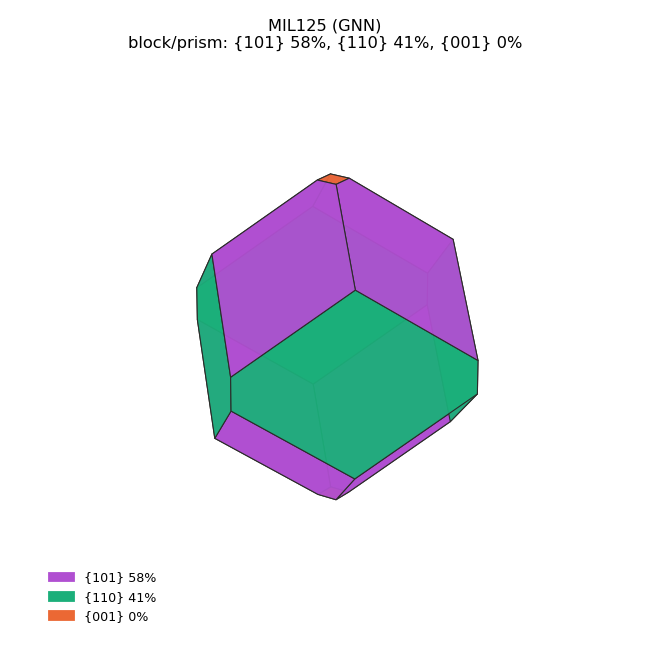

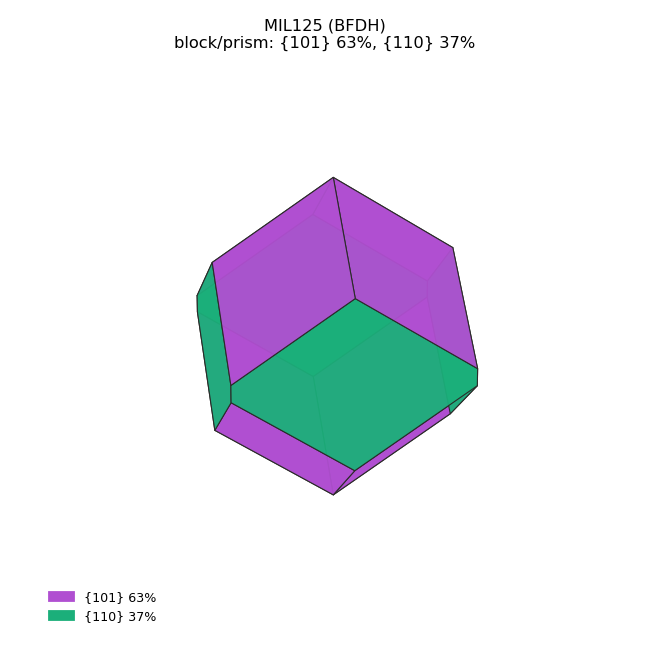

In [21]:
# 13. Predict the shape of a new MOF from its CIF: steps 1-5 + GNN (no CHGNet), with BFDH next to it
# Works in a fresh session: needs only cells 1, 2 (same SAVE_TO_DRIVE), the mofwulff cell and the mofgnn cell.
import sys, importlib; sys.path.insert(0, "/content")
import mofwulff as mw, mofgnn as G; importlib.reload(mw); importlib.reload(G)
from IPython.display import Image, display
from google.colab import files
MODELS, CK = G.load_models(f"{OUT_DIR}/gnn_surrogate.pt", graphs_dir=f"{OUT_DIR}/graphs")
print("GNN trained on:", CK["mofs"], "| elements:", CK.get("elements"))
up = files.upload(); fname = list(up)[0]; cif = "/content/" + fname; name = fname.rsplit(".", 1)[0]
df_new, summ, w_new, meta_new = G.predict_mof(MODELS, name, cif, target=CK["target"], train_elements=CK.get("elements"),
                                              n_families=4)
display(df_new[["face", "termination", "n_atoms", "n_water", "bonds_per_A2", "gamma_pred_J_m2"]].round(4))
for wmsg in summ["warnings"]:
    print("WARNING:", wmsg)
print("GNN shape :", summ["habit"], "| biggest face:", summ["dominant_face"])
print("BFDH shape:", summ["bfdh_habit"], "| biggest face:", summ["bfdh_dominant_face"], "| d_eff (A):", summ["d_eff"])
fams_new = G._families_from_meta(meta_new)[1]
for label, wv, hab in [("GNN", w_new, summ["habit"]), ("BFDH", meta_new["bfdh_wulff"], summ["bfdh_habit"])]:
    if wv is not None:
        display(Image(mw.render(wv, fams_new, f"{name} ({label})\n{hab}", f"/content/wulff_{name}_{label}.png")))

# 14. Morphology spectrum (structure only)

For one MOF this gives **the favoured shape** (from its computed γ) **and every distinct shape class its faces can form** when the relative face energies change. For each class it also gives **the smallest change in a γ ratio that reaches it**, and which face has to become cheaper or dearer. Inputs are the structure only: no solvent, temperature or additive fields, by design.

**How it works**
- *Map axes:* γ ratios relative to {100}, or to the first face if there is no {100}. A Wulff shape depends only on these ratios. Cubic: x = γ{110}/γ{100}, y = γ{111}/γ{100}.
- *Scan:* with up to 2 axes, a full grid (0.3–2.5, step 0.05, about 2,000 Wulff builds, around 10 s). With 3 or more axes (non-cubic with 4 faces), Sobol samples in batches until no new class appears (up to 4,096).
- *Shape class:* the shape name (rules from the project note) + the faces covering at least 5% of the surface. Truncated shapes are continuous families, so area fractions are given as ranges within a class.
- *Distance from the favoured shape:* `min_ratio_change_pct`, the smallest change in the γ ratio of two faces that reaches the class. This is the part that differs from MOF to MOF: for a cubic crystal the list of classes is set by symmetry, but how far each class is from the favoured point depends on the structure. It is refined by bisection, and every reported γ vector is re-checked to give its class.
- *BFDH* (1/d_eff, from the project note) is drawn on the map as a second point, with its distance from the favoured point.
- *γ ≤ 0* (e.g. CHGNet Mg-MOF-74, CALF-20-Cl): there is no favoured point, so there are no distances. The class list is still given, but then it only reflects symmetry and the face set.
- *Limits:* only low-index faces (`MAX_INDEX`), so {211} etc. can never appear. "All shapes" means all shapes of this face set.

**How to run (every case: run cells 1 and 2 with `SAVE_TO_DRIVE` ticked, then the `mofwulff`, `mofgnn` and `morphspec` cells)**

| You want | Then run |
|---|---|
| a new CIF, fast, with GNN γ | **14b** with `GAMMA_SOURCE = gnn` (uses the model saved by cell 12) |
| a new CIF, geometry only | **14b** with `GAMMA_SOURCE = bfdh` (no model, no GPU) |
| a new CIF with real CHGNet γ (slow, GPU) | cells 3 and 4 first, then **14b** with `GAMMA_SOURCE = chgnet` |
| every MOF already computed | **14c** (reads the cached CHGNet γ, no new calculations) |
| a check that the code is correct | **14a** (about 1 min; every line should say PASS) |

**Outputs** in `OUT_DIR/spectrum/<MOF>__<gamma source>/` (e.g. `ZIF-8__gnn`, `ZIF-8__bfdh`, `ZIF-8__CHGNet_relaxed`): `favoured_morphology.json`, `morphology_spectrum.json`, `morphology_spectrum.csv` (one row per shape class), `spectrum_map.png`, `spectrum_points.csv`, `wulff_favoured.png` and `.obj`, `wulff_<rank>_<class>.png` (up to 8), `spectrum_log.txt`. 14c also writes `spectrum/spectrum_summary_<relaxed|static>.csv`. Cell 8 zips everything if you run it again afterwards.

In [ ]:
%%writefile /content/morphspec.py
"""Morphology spectrum: every distinct Wulff shape class that a MOF's face set can produce when the
relative surface energies change, and how far each class is from the favoured (computed) shape.

Structure only, by design: no solvent, temperature, additive or concentration inputs anywhere.

Definitions (documented so the output can be defended):
  * Face set: the face families that have a gamma (from CHGNet, the GNN or BFDH). Low-index only
    (MAX_INDEX of the pipeline), so faces such as {211} can never appear.
  * Map axes: gamma ratios r_k = gamma_k / gamma_ref, ref = {100} if present, else the first family.
    A Wulff shape depends only on these ratios (it is scale-invariant), so n faces give n-1 axes.
    Cubic {100},{110},{111}: x = gamma{110}/gamma{100}, y = gamma{111}/gamma{100}.
  * Scan: up to 2 axes -> full grid (default 0.3..2.5, step 0.05, widened to include the favoured
    and BFDH points). 3 or more axes -> scrambled Sobol points, log-uniform in the same range, in
    batches until two batches in a row add no new class or max_samples is reached.
  * Shape class: habit label (mofwulff.name_habit, follows the project note) + the set of faces
    covering at least FACE_MIN of the surface. Truncated shapes are continuous families, so area
    fractions are reported as ranges inside a class, not used to split classes.
  * Distance from the favoured shape (the structure-specific result): for a gamma vector g and the
    favoured g0, spread = max_k ln(g_k/g0_k) - min_k ln(g_k/g0_k). It does not depend on the overall
    scale or on the choice of ref. Reported as min_ratio_change_pct = (exp(spread) - 1) * 100:
    "the gamma ratio of two faces must change by at least this much". lower_face is the face that
    becomes relatively cheaper, raise_face the one that becomes dearer. The closest scanned point of
    each class is refined by bisection along the straight line (in log-gamma space) from g0, and the
    returned gamma vector is re-checked to be in that class, so the number is an upper bound reached by
    a real, verified gamma vector.
  * Favoured gamma <= 0 (e.g. CHGNet for Mg-MOF-74, CALF-20-Cl): no favoured shape and no distances;
    the class list is still produced (it then reflects symmetry and face set only).
"""
import inspect
import itertools
import json
import math
import re
import tempfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
from pymatgen.core import Lattice, Structure

import mofwulff as mw
import mofgnn as G

FACE_MIN = 0.05                    # a face "is present" if it covers >= 5 % of the surface (same tolerance
                                   # as mofwulff.name_habit, which calls a shape a cube when {100} > 95 %)
PURE = {"cube": "{100}", "octahedron": "{111}", "rhombic_dodecahedron": "{110}"}
DEFAULT_GRID = (0.3, 2.5, 0.05)    # ratio range and step (spec: 0.3-2.5, step 0.02-0.05)
GAMMA_MIN = 1e-3                   # J/m^2; below this the favoured point is treated as undefined
FORBIDDEN_ARGS = ("solvent", "temperature", "temp", "additive", "modulator", "concentration", "time")


# ============================================================================ helpers
def _tag(name):
    return re.sub(r"[^\w.-]", "_", str(name))


def _face_order(name):
    """Sort face names like {100} < {110} < {111} < {2-10} by their digits."""
    return [int(x) for x in re.findall(r"\d", name)], name


def _dummy_conv(conv_lattice):
    return Structure(Lattice(conv_lattice), ["H"], [[0, 0, 0]])


def ratio_change(g, g0, keys):
    """(spread, lower key, raise key) between gamma vectors g and g0 (dicts), scale-free."""
    lr = np.array([math.log(g[k] / g0[k]) for k in keys])
    return float(lr.max() - lr.min()), keys[int(lr.argmin())], keys[int(lr.argmax())]


def pct(spread):
    return (math.exp(spread) - 1.0) * 100.0


# ============================================================================ B3: pure Wulff function
def wulff_from_gammas(conv, families, gammas, rotations, crystal_system, face_min=FACE_MIN, bounded=None):
    """gamma vector -> shape. Never raises.

    Returns dict(ok, habit, label, faces_present, class_id, area_fractions {face name: fraction},
    bounded, w) or dict(ok=False, reason=...)."""
    names = {f["key"]: f["name"] for f in families}
    g = {k: float(v) for k, v in gammas.items() if v is not None and np.isfinite(v)}
    if len(g) < 2:
        return dict(ok=False, reason="fewer than 2 faces with a gamma")
    bad = [names.get(k, k) for k, v in g.items() if v <= 0]
    if bad:
        return dict(ok=False, reason="gamma <= 0 for " + ", ".join(bad))
    try:
        w = mw.wulff(conv, families, g, rotations, bounded=bounded)
    except Exception as exc:                                        # degenerate polyhedron etc.
        return dict(ok=False, reason=f"Wulff failed: {type(exc).__name__}: {exc}")
    if w is None:
        return dict(ok=False, reason="no faces")
    habit = mw.name_habit(w, families, crystal_system, conv)
    label = G.habit_class(habit)
    fr = {names.get(k, k): float(v) for k, v in w["area_fractions"].items() if k != "open"}
    present = tuple(sorted((n for n, v in fr.items() if v >= face_min), key=_face_order))
    if label in PURE:                       # pure shapes: one face by definition (name tolerance = 5 %)
        present = (PURE[label],)
    elif crystal_system == "cubic" and len(present) == 1 and present[0] in PURE.values():
        # only one face covers >= 5 %: two small facets (< 5 % each) do not make it a truncated shape
        label = {v: k for k, v in PURE.items()}[present[0]]
    return dict(ok=True, habit=habit if G.habit_class(habit) == label or crystal_system != "cubic" else label,
                label=label, faces_present=present,
                class_id=f"{label} | {'+'.join(present)}", area_fractions=fr, bounded=bool(w["bounded"]), w=w)


# ============================================================================ B1: scan
def scan_morphology_map(conv, families, rotations, crystal_system, gamma_favoured, gamma_bfdh=None,
                        grid=DEFAULT_GRID, max_samples=4096, batch=512, face_min=FACE_MIN, refine_steps=12,
                        seed=0, keep_points=True, log=print):
    """All shape classes reachable by changing relative gammas of the given faces (structure only).

    gamma_favoured: {family key: gamma} from CHGNet / GNN / BFDH. Families without a gamma are left out.
    gamma_bfdh:     optional {family key: 1/d_eff}, placed on the map as a second point.
    Returns a result dict (see module docstring); raises ValueError if fewer than 2 faces have a gamma.
    """
    t0 = time.time()
    keys = [f["key"] for f in families
            if f["key"] in gamma_favoured and gamma_favoured[f["key"]] is not None
            and np.isfinite(gamma_favoured[f["key"]])]
    if len(keys) < 2:
        raise ValueError(f"Morphology spectrum needs a gamma for at least 2 face families; got {len(keys)} "
                         f"({[f['name'] for f in families if f['key'] in keys]}). "
                         "Check that the slabs for this MOF could be cut and healed.")
    fams = [f for f in families if f["key"] in keys]
    names = {f["key"]: f["name"] for f in fams}
    ref = next((f["key"] for f in fams if f["name"] == "{100}"), keys[0])
    free = [k for k in keys if k != ref]
    dims = len(free)
    g0 = {k: float(gamma_favoured[k]) for k in keys}
    fav_ok = min(g0.values()) > GAMMA_MIN
    gb = None
    if gamma_bfdh and all(k in gamma_bfdh and gamma_bfdh[k] and gamma_bfdh[k] > 0 for k in keys):
        gb = {k: float(gamma_bfdh[k]) for k in keys}

    def ratios_of(g):
        return tuple(g[k] / g[ref] for k in free)

    def gammas_of(r):
        return {ref: 1.0, **{k: float(x) for k, x in zip(free, r)}}

    # Whether the polyhedron is closed depends only on the plane set, so check it once (mofwulff.wulff).
    probe = wulff_from_gammas(conv, fams, {k: 1.0 for k in keys}, rotations, crystal_system, face_min)
    closed = True if probe.get("ok") and probe["bounded"] else None

    cache = {}

    def evaluate(g):
        key = tuple(round(g[k] / g[ref], 6) for k in free)
        if key not in cache:
            cache[key] = wulff_from_gammas(conv, fams, g, rotations, crystal_system, face_min, bounded=closed)
        return cache[key]

    lo, hi, step = (float(x) for x in grid)
    special = [r for r in ([ratios_of(g0)] if fav_ok else []) + ([ratios_of(gb)] if gb else [])]
    if special:
        lo = min(lo, 0.9 * min(min(r) for r in special))
        hi = max(hi, 1.1 * max(max(r) for r in special))
    points, failures = [], []

    def add_point(r, kind):
        res = evaluate(gammas_of(r))
        rec = {**{f"r_{names[k]}": x for k, x in zip(free, r)}, "kind": kind, "ok": res["ok"],
               "class_id": res.get("class_id"), "reason": None if res["ok"] else res["reason"]}
        points.append(rec)
        if not res["ok"]:
            failures.append(rec)
        return res

    if dims <= 2:
        method = "grid"
        axis = np.round(np.arange(lo, hi + step / 2, step), 6)
        for r in itertools.product(axis, repeat=dims):
            add_point(r, "grid")
    else:
        method = "sobol"
        import warnings
        from scipy.stats import qmc
        warnings.filterwarnings("ignore", message=".*balance properties of Sobol.*")
        sob = qmc.Sobol(d=dims, scramble=True, seed=seed)
        seen, quiet, n = set(), 0, 0
        while n < max_samples and quiet < 2:
            u = sob.random(min(batch, max_samples - n))
            new = 0
            for row in np.exp(np.log(lo) + u * (np.log(hi) - np.log(lo))):
                res = add_point(tuple(float(x) for x in row), "sample")
                if res["ok"] and res["class_id"] not in seen:
                    seen.add(res["class_id"]); new += 1
            n += len(u)
            quiet = quiet + 1 if new == 0 else 0
    n_scan = len(points)
    fav = add_point(ratios_of(g0), "favoured") if fav_ok else None
    bf = add_point(ratios_of(gb), "bfdh") if gb else None

    # ---------------------------------------------------------------- aggregate classes
    P = pd.DataFrame(points)
    rcols = [f"r_{names[k]}" for k in free]
    classes = {}
    for _, row in P[P["ok"]].iterrows():
        cid = row["class_id"]
        r = tuple(row[c] for c in rcols)
        res = evaluate(gammas_of(r))
        c = classes.setdefault(cid, dict(class_id=cid, label=res["label"], faces_present=list(res["faces_present"]),
                                         example_habit=res["habit"], n_scan_points=0, area_min={}, area_max={},
                                         members=[], contains_favoured=False, contains_bfdh=False))
        if row["kind"] in ("grid", "sample"):
            c["n_scan_points"] += 1
        c["contains_favoured"] |= row["kind"] == "favoured"
        c["contains_bfdh"] |= row["kind"] == "bfdh"
        for f, v in res["area_fractions"].items():
            if v >= face_min:
                c["area_min"][f] = min(c["area_min"].get(f, 1.0), v)
                c["area_max"][f] = max(c["area_max"].get(f, 0.0), v)
        c["members"].append(r)
    n_ok_scan = int(P.iloc[:n_scan]["ok"].sum()) if n_scan else 0

    # ---------------------------------------------------------------- distances (structure-specific part)
    for cid, c in classes.items():
        c["map_fraction"] = c["n_scan_points"] / n_ok_scan if n_ok_scan else 0.0
        if not fav_ok:
            mean = np.exp(np.mean(np.log(np.array(c["members"])), axis=0))      # central point of the class
            r = min(c["members"], key=lambda m: float(np.sum((np.log(m) - np.log(mean)) ** 2)))
            c.update(rep_gammas=gammas_of(r), spread=np.nan, lower_face=None, raise_face=None)
            continue
        if c["contains_favoured"]:
            c.update(rep_gammas=dict(g0), spread=0.0, lower_face=None, raise_face=None)
            continue
        cand = sorted(c["members"], key=lambda m: ratio_change(gammas_of(m), g0, keys)[0])[:3]
        best = None
        for m in cand:
            p = gammas_of(m)
            lo_t, hi_t = 0.0, 1.0
            for _ in range(refine_steps):
                mid = 0.5 * (lo_t + hi_t)
                q = {k: g0[k] ** (1 - mid) * p[k] ** mid for k in keys}
                rq = evaluate(q)
                if rq["ok"] and rq["class_id"] == cid:
                    hi_t = mid
                else:
                    lo_t = mid
            q = {k: g0[k] ** (1 - hi_t) * p[k] ** hi_t for k in keys}
            chk = evaluate(q)
            if not (chk["ok"] and chk["class_id"] == cid):          # safety: keep the scanned point
                q = p
            s, lw, rs = ratio_change(q, g0, keys)
            if best is None or s < best[0]:
                best = (s, lw, rs, q)
        s, lw, rs, q = best
        c.update(rep_gammas=q, spread=s, lower_face=names[lw], raise_face=names[rs])

    order = sorted(classes.values(), key=lambda c: (np.nan_to_num(c["spread"], nan=9e9), -c["map_fraction"]))
    for i, c in enumerate(order):
        c["rank"] = i
        c["min_ratio_change_pct"] = round(pct(c["spread"]), 1) if np.isfinite(c["spread"]) else None
        c["rep_ratios"] = {names[k]: round(c["rep_gammas"][k] / c["rep_gammas"][ref], 4) for k in free}
        c.pop("members")

    bf_info = None
    if gb is not None:
        bf_info = dict(gammas={names[k]: v for k, v in gb.items()}, ratios=dict(zip([names[k] for k in free], ratios_of(gb))),
                       ok=bf["ok"], habit=bf.get("habit"), class_id=bf.get("class_id"),
                       area_fractions=bf.get("area_fractions"))
        if fav_ok:
            s, lw, rs = ratio_change(gb, g0, keys)
            bf_info.update(ratio_change_from_favoured_pct=round(pct(s), 1), lower_face=names[lw], raise_face=names[rs])

    favoured = dict(defined=fav_ok, gammas={names[k]: v for k, v in g0.items()},
                    ratios=dict(zip([names[k] for k in free], ratios_of(g0))) if fav_ok else None)
    if fav_ok:
        favoured.update(ok=fav["ok"], habit=fav.get("habit"), class_id=fav.get("class_id"),
                        area_fractions=fav.get("area_fractions"), reason=fav.get("reason"))
    else:
        favoured["reason"] = "gamma <= 0 (or ~0) for " + ", ".join(names[k] for k in keys if g0[k] <= GAMMA_MIN)
    warnings_ = []
    if fav_ok:
        med = float(np.median(list(g0.values())))
        tiny = [names[k] for k in keys if g0[k] < 0.05 * med]
        if tiny:
            warnings_.append(f"gamma of {tiny} is < 5 % of the median face: that face is almost free to form, "
                             "so the favoured point sits far from the others and distances become very large. "
                             "Check that slab (relaxation, healing) before using these numbers.")

    out = dict(faces=[names[k] for k in keys], face_keys=keys, ref_face=names[ref], axes=[names[k] for k in free],
               crystal_system=crystal_system, method=method, range=(lo, hi), step=step if method == "grid" else None,
               n_scan_points=n_scan, n_failed=len(failures), failure_examples=failures[:5],
               favoured=favoured, bfdh=bf_info, classes=order, unique_habits=[c["class_id"] for c in order],
               seconds=round(time.time() - t0, 1), points=P if keep_points else None, closed_shape=closed is True,
               warnings=warnings_)
    if log:
        log(f"   spectrum: {len(keys)} faces {out['faces']}, {method} {n_scan} points "
            f"({len(failures)} failed) -> {len(order)} shape classes in {out['seconds']} s")
    return out


# ============================================================================ E: outputs
def _clean(o):
    """JSON-safe copy: numpy -> python, NaN/inf -> None, tuples/sets -> lists."""
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [_clean(v) for v in o]
    if isinstance(o, np.generic):
        o = o.item()
    if isinstance(o, float) and not np.isfinite(o):
        return None
    if isinstance(o, (str, int, float, bool)) or o is None:
        return o
    return str(o)


def plot_map(res, path, title=""):
    import matplotlib
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    P = res["points"]
    cls = res["classes"]
    cmap20 = matplotlib.colormaps["tab20"]
    color = {c["class_id"]: cmap20(i % 20) for i, c in enumerate(cls)}
    idx = {c["class_id"]: i for i, c in enumerate(cls)}
    axes = [f"r_{a}" for a in res["axes"]]
    ref = res["ref_face"]
    fig, ax = plt.subplots(figsize=(8.6, 5.6))
    scan = P[P["kind"].isin(["grid", "sample"])]
    if res["method"] == "grid" and len(axes) == 2:
        xs, ys = np.sort(scan[axes[0]].unique()), np.sort(scan[axes[1]].unique())
        Z = np.full((len(ys), len(xs)), np.nan)
        xi = {v: i for i, v in enumerate(xs)}; yi = {v: i for i, v in enumerate(ys)}
        for _, r in scan.iterrows():
            if r["ok"]:
                Z[yi[r[axes[1]]], xi[r[axes[0]]]] = idx[r["class_id"]]
        cm = ListedColormap([color[c["class_id"]] for c in cls])
        ax.pcolormesh(xs, ys, np.ma.masked_invalid(Z), cmap=cm, vmin=-0.5, vmax=len(cls) - 0.5, shading="nearest")
        ax.set_xlabel(f"γ{res['axes'][0]} / γ{ref}"); ax.set_ylabel(f"γ{res['axes'][1]} / γ{ref}")
        xcol, ycol = axes
    elif len(axes) == 1:
        xs = np.sort(scan[axes[0]].unique())
        Z = np.array([[idx.get(scan[scan[axes[0]] == x]["class_id"].iloc[0], np.nan)
                       if scan[scan[axes[0]] == x]["ok"].iloc[0] else np.nan for x in xs]])
        cm = ListedColormap([color[c["class_id"]] for c in cls])
        ax.pcolormesh(xs, [0, 1], np.vstack([Z, Z]), cmap=cm, vmin=-0.5, vmax=len(cls) - 0.5, shading="nearest")
        ax.set_yticks([]); ax.set_xlabel(f"γ{res['axes'][0]} / γ{ref}")
        xcol, ycol = axes[0], None
    else:
        # 3+ ratio axes cannot be drawn as a map: show what matters instead, each class's distance from the
        # favoured shape (or, with no favoured point, its share of the scanned space)
        plt.close(fig)
        n = len(cls)
        fig, ax = plt.subplots(figsize=(8.6, max(3.0, 0.32 * n + 1.2)))
        fav_def = any(c["min_ratio_change_pct"] is not None for c in cls)
        vals = [(c["min_ratio_change_pct"] if fav_def else 100 * c["map_fraction"]) or 0.0 for c in cls]
        ys = np.arange(n)[::-1]
        bars = ax.barh(ys, vals, color=[color[c["class_id"]] for c in cls], edgecolor="none")
        for y, c, v in zip(ys, cls, vals):
            tag = "  favoured" if c["contains_favoured"] else ""
            tag += "  BFDH" if c["contains_bfdh"] else ""
            ax.text(v, y, f" {v:.1f}%{tag}", va="center", fontsize=7)
        ax.set_yticks(ys); ax.set_yticklabels([c["class_id"] for c in cls], fontsize=7)
        ax.set_xlabel("smallest change in a γ ratio that reaches the class (%)" if fav_def
                      else "share of the scanned ratio space (%)  [no favoured point: γ <= 0]")
        if fav_def and max(vals) > 0:
            ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, max(vals) * 3)
        ax.set_title(title + f"\n{len(axes)} ratio axes ({', '.join(res['axes'])} / {ref}): shown as distance from the favoured shape",
                     fontsize=8)
        fig.tight_layout(); fig.savefig(path, dpi=130); plt.close(fig)
        return str(path)
    for kind, mk, fc, lab in (("bfdh", "^", "white", "BFDH (1/d_eff)"), ("favoured", "*", "black", "favoured (computed γ)")):
        q = P[P["kind"] == kind]
        if len(q):
            yv = q[ycol].iloc[0] if ycol else 0.5
            ax.scatter([q[xcol].iloc[0]], [yv], marker=mk, s=220 if mk == "*" else 110, c=fc,
                       edgecolors="black", linewidths=1.0, zorder=5, label=lab)
    handles = [plt.Rectangle((0, 0), 1, 1, color=color[c["class_id"]]) for c in cls]
    labels = [c["class_id"] + (f"  ({c['min_ratio_change_pct']:.0f}%)" if c["min_ratio_change_pct"] is not None else "")
              for c in cls]
    l1 = ax.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=7, frameon=False,
                   title="shape class (min γ-ratio change)", title_fontsize=7)
    ax.add_artist(l1)
    ax.legend(loc="lower left", bbox_to_anchor=(1.01, 0.0), fontsize=7, frameon=False)
    ax.set_title(title, fontsize=9)
    fig.tight_layout(); fig.savefig(path, dpi=130); plt.close(fig)
    return str(path)


def write_outputs(res, out_dir, name, conv, families, rotations, gamma_source, notes=(), max_images=8):
    """favoured_morphology.json, morphology_spectrum.json/.csv, spectrum_map.png, Wulff images, log."""
    d = Path(out_dir) / "spectrum" / f"{_tag(name)}__{_tag(gamma_source)}"     # one folder per MOF and gamma source
    d.mkdir(parents=True, exist_ok=True)
    fams = [f for f in families if f["key"] in res["face_keys"]]
    key_of = {f["name"]: f["key"] for f in fams}
    files = {}
    fav = res["favoured"]
    favj = dict(mof=name, gamma_source=gamma_source, faces=res["faces"], map_axes=res["axes"], ref_face=res["ref_face"],
                favoured_defined=fav["defined"], gamma_J_m2=fav["gammas"], map_coordinates=fav.get("ratios"),
                habit=fav.get("habit"), class_id=fav.get("class_id"), area_fractions=fav.get("area_fractions"),
                reason=fav.get("reason"), bfdh=res["bfdh"], warnings=res.get("warnings", []), notes=list(notes) + [
                    "Structure only: shapes reachable by changing relative energies of the listed low-index faces. "
                    "Solvent, temperature and additives are not modelled."])
    (d / "favoured_morphology.json").write_text(json.dumps(_clean(favj), indent=1, allow_nan=False)); files["favoured_json"] = str(d / "favoured_morphology.json")
    rows = []
    for c in res["classes"]:
        rows.append(dict(rank=c["rank"], class_id=c["class_id"], label=c["label"], faces_present="+".join(c["faces_present"]),
                         is_favoured=c["contains_favoured"], contains_bfdh=c["contains_bfdh"],
                         map_fraction=round(c["map_fraction"], 4), min_ratio_change_pct=c["min_ratio_change_pct"],
                         lower_face=c["lower_face"], raise_face=c["raise_face"],
                         representative_ratios=json.dumps(c["rep_ratios"]),
                         area_fraction_ranges=json.dumps({f: [round(c["area_min"][f], 3), round(c["area_max"][f], 3)]
                                                          for f in sorted(c["area_min"], key=_face_order)}),
                         example_habit=c["example_habit"]))
    table = pd.DataFrame(rows)
    table.to_csv(d / "morphology_spectrum.csv", index=False); files["spectrum_csv"] = str(d / "morphology_spectrum.csv")
    specj = {k: v for k, v in res.items() if k not in ("points",)}
    specj["classes"] = [{k: v for k, v in c.items() if k != "rep_gammas"} | {"rep_gammas": {n: c["rep_gammas"][key_of[n]] for n in key_of}}
                        for c in res["classes"]]
    specj["mof"] = name; specj["gamma_source"] = gamma_source
    (d / "morphology_spectrum.json").write_text(json.dumps(_clean(specj), indent=1, allow_nan=False))
    files["spectrum_json"] = str(d / "morphology_spectrum.json")
    if res["points"] is not None:
        res["points"].to_csv(d / "spectrum_points.csv", index=False)
        files["map_png"] = plot_map(res, d / "spectrum_map.png",
                                    f"{name}: morphology spectrum ({gamma_source} γ, {res['method']}, {res['n_scan_points']} points)")
    if fav["defined"] and fav.get("ok"):
        w = mw.wulff(conv, fams, {key_of[n]: v for n, v in fav["gammas"].items()}, rotations)
        files["favoured_png"] = mw.render(w, fams, f"{name} favoured ({gamma_source})\n{fav['habit']}", d / "wulff_favoured.png")
        mw.write_obj(w, d / "wulff_favoured.obj"); files["favoured_obj"] = str(d / "wulff_favoured.obj")
    files["class_pngs"] = []
    for c in res["classes"][:max_images]:
        w = mw.wulff(conv, fams, c["rep_gammas"], rotations)
        tag = f"wulff_{c['rank']:02d}_{_tag(c['label'])}.png"
        sub = f"min change {c['min_ratio_change_pct']}%" if c["min_ratio_change_pct"] is not None else ""
        files["class_pngs"].append(mw.render(w, fams, f"{c['class_id']}\n{sub}", d / tag))
    logtxt = [f"MOF {name} | gamma source {gamma_source}", f"faces {res['faces']} (ref {res['ref_face']}, axes {res['axes']})",
              f"favoured gamma {fav['gammas']} -> {fav.get('habit') or fav.get('reason')}",
              f"method {res['method']} range {res['range']} step {res['step']} points {res['n_scan_points']} "
              f"failed {res['n_failed']} closed-shape check skipped {res['closed_shape']}",
              f"{len(res['classes'])} shape classes: " + "; ".join(res["unique_habits"]),
              f"time {res['seconds']} s"] + [f"failure example: {f}" for f in res["failure_examples"]] + list(notes) \
             + [f"WARNING: {w}" for w in res.get("warnings", [])]
    (d / "spectrum_log.txt").write_text("\n".join(logtxt)); files["log"] = str(d / "spectrum_log.txt")
    files["dir"] = str(d)
    return table, files


# ============================================================================ D: entry points
def _gammas_from_rows(rows, cap="water", mode="relaxed"):
    """Lowest gamma per family from slab rows (CSV-safe: NaN -> None, 'True' -> True)."""
    clean = []
    for r in rows:
        r = {k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in r.items()}
        cv = r.get("converged")
        r["converged"] = cv is True or (isinstance(cv, str) and cv.strip().lower() == "true") or cv == 1
        clean.append(r)
    best = mw.choose_gamma(clean, cap, need_relaxed=(mode == "relaxed"))
    return {k: b["gamma"] for k, b in best.items()}, best


def spectrum_from_pipeline(out_dir, mof, gamma_mode="relaxed", cap="water", grid=DEFAULT_GRID, max_samples=4096,
                           max_images=8, write=True, log=print):
    """Spectrum for a MOF the pipeline already computed (reads the cache; no new CHGNet).
    gamma_mode: 'relaxed' (converged relaxed gamma, as in step 8) or 'static'."""
    out_dir = Path(out_dir)
    meta = G.load_meta(out_dir, mof)
    conv, fams, rots = G._families_from_meta(meta)
    if (out_dir / "slabs_all.csv").exists():
        df = pd.read_csv(out_dir / "slabs_all.csv")
    else:
        parts = [pd.read_csv(out_dir / f) for f in ("slabs.csv", "slabs_train.csv", "slabs_static.csv") if (out_dir / f).exists()]
        if not parts:
            raise FileNotFoundError(f"no slabs CSV in {out_dir}")
        df = pd.concat(parts, ignore_index=True)
    rows = df[df["mof"] == mof].to_dict("records")
    if not rows:
        raise ValueError(f"{mof}: no slab rows in the results CSVs")
    gam, best = _gammas_from_rows(rows, cap, gamma_mode)
    tbl = G.bfdh_for_mof(out_dir, mof)
    gb = {k: 1.0 / v["d_eff"] for k, v in tbl.items()} if tbl else None
    notes = [] if tbl else ["BFDH point missing: the CIF for this MOF is not in this session (run cell 3, or upload it)."]
    missing = [f["name"] for f in fams if f["key"] not in gam]
    if missing:
        notes.append(f"faces without a {gamma_mode} gamma (left out of the map): {missing}")
    res = scan_morphology_map(conv, fams, rots, meta["crystal_system"], gam, gb, grid, max_samples, log=log)
    table, files = write_outputs(res, out_dir, mof, conv, fams, rots, f"CHGNet {gamma_mode}", notes, max_images) if write else (None, {})
    return _package(res, table, files, notes)


def run_spectrum(cif, name, out_dir, gamma_source="gnn", models=None, train_elements=None, gnn_target="gamma",
                 engine=None, pipeline_cfg=None, symprec=0.1, disorder="majority", max_index=1, n_families=4,
                 grid=DEFAULT_GRID, max_samples=4096, max_images=8, log=print):
    """One CIF -> favoured shape + every shape class its faces can produce + distances.

    gamma_source: 'gnn'    steps 1-5 + the trained GNN (seconds; needs models from mofgnn.load_models)
                  'chgnet' full pipeline steps 1-6 via mofwulff.run_mof (slow, cached; needs engine + pipeline_cfg)
                  'bfdh'   geometry only, gamma ~ 1/d_eff (instant)
    No solvent / temperature / additive arguments, by design."""
    notes = []
    if gamma_source == "gnn":
        if not models:
            raise ValueError("gamma_source='gnn' needs models (mofgnn.load_models)")
        df, summ, w, meta = G.predict_mof(models, name, cif, target=gnn_target, train_elements=train_elements,
                                          symprec=symprec, disorder=disorder, max_index=max_index, n_families=n_families)
        conv, fams, rots = G._families_from_meta(meta)
        gam = summ["gammas"]
        gb = {k: 1.0 / v["d_eff"] for k, v in meta["bfdh"].items()}
        notes += [f"GNN warning: {x}" for x in summ["warnings"]]
        cs = meta["crystal_system"]
    elif gamma_source == "chgnet":
        if engine is None or pipeline_cfg is None:
            raise ValueError("gamma_source='chgnet' needs engine (mofwulff.Engine()) and pipeline_cfg (settings dict)")
        meta, fams, recs, bulk = mw.run_mof(engine, name, cif, out_dir, **pipeline_cfg)
        conv = _dummy_conv(meta["conv_lattice"]); rots = [np.array(r) for r in meta["_rotations"]]
        mode = "relaxed" if pipeline_cfg.get("relax_steps", mw.DEFAULTS.get("relax_steps", 0)) else "static"
        gam, best = _gammas_from_rows(recs, pipeline_cfg.get("cap", "water"), mode)
        tbl = G.bfdh_for_mof(out_dir, name)
        gb = {k: 1.0 / v["d_eff"] for k, v in tbl.items()} if tbl else None
        cs = meta["crystal_system"]
        notes.append(f"CHGNet gamma ({mode})")
    elif gamma_source == "bfdh":
        info = mw.standardize(cif, symprec, disorder)
        fams = mw.face_families(info["conv"], info["rotations"], max_index, n_families)
        tbl = G.d_eff_table(info, fams)
        gam = {k: 1.0 / v["d_eff"] for k, v in tbl.items()}
        gb = dict(gam)
        conv = _dummy_conv(info["conv"].lattice.matrix.tolist()); rots = info["rotations"]
        cs = info["crystal_system"]
        notes.append("BFDH: gamma taken proportional to 1/d_eff (geometry only, no energies)")
    else:
        raise ValueError(f"gamma_source must be 'gnn', 'chgnet' or 'bfdh', not {gamma_source!r}")
    res = scan_morphology_map(conv, fams, rots, cs, gam, gb, grid, max_samples, log=log)
    label = f"CHGNet {mode}" if gamma_source == "chgnet" else gamma_source    # same folder name as 14c
    table, files = write_outputs(res, out_dir, name, conv, fams, rots, label, notes, max_images)
    return _package(res, table, files, notes)


def _package(res, table, files, notes):
    fav = res["favoured"]
    notes = list(notes) + [f"WARNING: {w}" for w in res.get("warnings", [])]
    return dict(favoured=fav, unique_habits=res["unique_habits"], classes=res["classes"], table=table,
                grid_points=res["points"], map_coordinates_of_favoured=fav.get("ratios"), face_list=res["faces"],
                gamma_dict=fav["gammas"], bfdh=res["bfdh"], files=files, notes=list(notes), result=res)


# ============================================================================ G: tests
def _cubic_setup():
    from pymatgen.symmetry.analyzer import SpacegroupAnalyzer
    st = Structure.from_spacegroup("Fm-3m", Lattice.cubic(5.64), ["Na", "Cl"], [[0, 0, 0], [0.5, 0.5, 0.5]])
    rots = []
    for op in SpacegroupAnalyzer(st).get_symmetry_operations():
        R = np.round(op.rotation_matrix).astype(int)
        if not any(np.array_equal(R, q) for q in rots):
            rots.append(R)
    return st, mw.face_families(st, rots, faces=[(1, 0, 0), (1, 1, 0), (1, 1, 1)]), rots


def _tetragonal_setup():
    from pymatgen.symmetry.analyzer import SpacegroupAnalyzer
    st = Structure.from_spacegroup("I4/mmm", Lattice.tetragonal(10.0, 14.0), ["Zn", "O"], [[0, 0, 0], [0, 0, 0.3]])
    rots = []
    for op in SpacegroupAnalyzer(st).get_symmetry_operations():
        R = np.round(op.rotation_matrix).astype(int)
        if not any(np.array_equal(R, q) for q in rots):
            rots.append(R)
    return st, mw.face_families(st, rots, 1, 4), rots


def run_self_tests(cifs=(), verbose=True):
    """Spec section G. cifs: optional [(path, expected BFDH habit label)] for real-structure checks."""
    say = print if verbose else (lambda *a: None)
    results = []

    def check(name, cond, detail=""):
        results.append((name, bool(cond), detail)); say(("PASS " if cond else "FAIL ") + name + (f"  [{detail}]" if detail else ""))

    st, fams, rots = _cubic_setup()
    K = {f["name"]: f["key"] for f in fams}
    one = lambda a, b, c: {K["{100}"]: a, K["{110}"]: b, K["{111}"]: c}
    r = wulff_from_gammas(st, fams, one(1.0, 2.0, 2.0), rots, "cubic")
    check("pure cube gamma -> cube, only {100}", r["ok"] and r["label"] == "cube" and r["faces_present"] == ("{100}",), r.get("class_id"))
    r = wulff_from_gammas(st, fams, one(2.0, 2.0, 1.0), rots, "cubic")
    check("pure octahedron gamma -> octahedron, only {111}", r["ok"] and r["label"] == "octahedron" and r["faces_present"] == ("{111}",), r.get("class_id"))
    r = wulff_from_gammas(st, fams, one(2.0, 1.0, 2.0), rots, "cubic")
    check("pure dodecahedron gamma -> rhombic_dodecahedron", r["ok"] and r["label"] == "rhombic_dodecahedron", r.get("class_id"))
    r = wulff_from_gammas(st, fams, one(1.0, 2.0, 2 / math.sqrt(3)), rots, "cubic")
    check("R111/R100 = 2/sqrt3 -> cuboctahedron (project note, Step 11)", r["ok"] and r["label"] == "cuboctahedron", r.get("class_id"))
    r = wulff_from_gammas(st, fams, one(1.0, 1.0, -0.1), rots, "cubic")
    check("gamma <= 0 -> clean refusal, no crash", not r["ok"] and "gamma <= 0" in r["reason"], r.get("reason"))

    fav = one(1.0, 1.4, 0.85)                       # a truncated octahedron
    grid = (0.3, 2.5, 0.1)
    s1 = scan_morphology_map(st, fams, rots, "cubic", fav, None, grid, log=None)
    labels = {c["label"] for c in s1["classes"]}
    need = {"cube", "octahedron", "rhombic_dodecahedron", "truncated_octahedron", "truncated_cube"}
    check("cubic spectrum contains cube, octahedron, dodecahedron and both truncations", need <= labels, sorted(labels))
    check("favoured point is a truncated octahedron at distance 0",
          s1["favoured"]["habit"] == "truncated_octahedron" and s1["classes"][0]["contains_favoured"] and s1["classes"][0]["spread"] == 0.0)
    cube = next(c for c in s1["classes"] if c["label"] == "cube")
    check("cube is reached by making {100} cheaper relative to {111}",
          cube["lower_face"] == "{100}" or cube["raise_face"] == "{111}",
          f"{cube['min_ratio_change_pct']}%: lower {cube['lower_face']}, raise {cube['raise_face']}")
    ok_rep = all(wulff_from_gammas(st, fams, c["rep_gammas"], rots, "cubic")["class_id"] == c["class_id"] for c in s1["classes"])
    check("every class's representative gamma vector really gives that class", ok_rep)
    # independent check: walk gamma{111} up from the favoured point until the shape is called a cube
    lo_y, hi_y = fav[K["{111}"]], 3.0
    for _ in range(40):
        mid = 0.5 * (lo_y + hi_y)
        rr = wulff_from_gammas(st, fams, one(1.0, max(1.4, 1.5), mid), rots, "cubic")
        lo_y, hi_y = (lo_y, mid) if rr["ok"] and rr["label"] == "cube" else (mid, hi_y)
    direct = (hi_y / fav[K["{111}"]] - 1) * 100
    check("cube distance <= the change found by a direct 1-D walk (scan finds the shortest route)",
          cube["min_ratio_change_pct"] <= direct * 1.01, f"scan {cube['min_ratio_change_pct']}% vs direct walk {direct:.1f}%")
    # geometry check against the analytic result: {111} vanishes from a {100}+{111} crystal at R111/R100 = sqrt3
    lo_y, hi_y = 1.0, 3.0
    for _ in range(40):
        mid = 0.5 * (lo_y + hi_y)
        rr = wulff_from_gammas(st, fams, one(1.0, 2.0, mid), rots, "cubic")
        lo_y, hi_y = (lo_y, mid) if rr["area_fractions"].get("{111}", 0.0) < 1e-9 else (mid, hi_y)
    check("Wulff geometry: {111} vanishes exactly at gamma111/gamma100 = sqrt3 (analytic 1.7321)",
          abs(hi_y - math.sqrt(3)) < 1e-3, f"{hi_y:.4f}")
    check("the named cube boundary (< 5 % {111}) comes before the full vanishing point",
          cube["min_ratio_change_pct"] < (math.sqrt(3) / 0.85 - 1) * 100, f"{cube['min_ratio_change_pct']}% < 103.8%")
    s2 = scan_morphology_map(st, fams, rots, "cubic", fav, None, grid, log=None)
    same = [(c["class_id"], c["n_scan_points"], c["min_ratio_change_pct"]) for c in s1["classes"]] == \
           [(c["class_id"], c["n_scan_points"], c["min_ratio_change_pct"]) for c in s2["classes"]]
    check("same gamma twice -> identical spectrum", same)
    try:
        scan_morphology_map(st, fams, rots, "cubic", {K["{100}"]: 1.0}, None, grid, log=None)
        check("one face only -> clear error", False)
    except ValueError as e:
        check("one face only -> clear error", "at least 2 face families" in str(e), str(e)[:70])
    s3 = scan_morphology_map(st, fams, rots, "cubic", one(1.0, 1.2, -0.05), None, grid, log=None)
    check("favoured gamma <= 0 -> spectrum still listed, no distances",
          not s3["favoured"]["defined"] and len(s3["classes"]) >= 5 and all(c["min_ratio_change_pct"] is None for c in s3["classes"]))
    st2 = scan_morphology_map(st, fams, rots, "cubic", {K["{100}"]: 1.0, K["{111}"]: 0.9}, None, grid, log=None)
    check("two faces -> 1-D scan runs", st2["method"] == "grid" and len(st2["axes"]) == 1 and len(st2["classes"]) >= 3,
          [c["label"] for c in st2["classes"]])

    tst, tfams, trots = _tetragonal_setup()
    tg = {f["key"]: 1.0 + 0.1 * i for i, f in enumerate(tfams)}
    t0 = time.time()
    s4 = scan_morphology_map(tst, tfams, trots, "tetragonal", tg, None, grid, max_samples=1024, log=None)
    check(f"non-cubic ({len(tfams)} faces, {len(tfams) - 1}-D) Sobol scan runs", s4["method"] == "sobol" and len(s4["classes"]) >= 2,
          f"{len(s4['classes'])} classes, {s4['n_scan_points']} points, {time.time() - t0:.0f} s")

    banned = []
    for fn in (scan_morphology_map, run_spectrum, spectrum_from_pipeline):
        banned += [f"{fn.__name__}({p})" for p in inspect.signature(fn).parameters if any(b in p.lower() for b in FORBIDDEN_ARGS)]
    check("no solvent / temperature / additive arguments in the API", not banned, banned)

    for path, expect in cifs:
        if not Path(path).exists():
            say(f"SKIP {path} (not found)"); continue
        with tempfile.TemporaryDirectory() as tmp:
            out = run_spectrum(path, Path(path).stem, tmp, gamma_source="bfdh", grid=(0.3, 2.5, 0.1), max_images=2, log=None)
            got = out["favoured"].get("habit")
            check(f"{Path(path).name}: BFDH favoured shape = {expect}", G.habit_class(got) == expect,
                  f"{got}; {len(out['unique_habits'])} classes; files written: {sorted(k for k in out['files'] if k != 'class_pngs')}")
    n_fail = sum(not ok for _, ok, _ in results)
    say(f"\n{len(results) - n_fail}/{len(results)} tests passed")
    return results


# ============================================================================ notebook helpers
def _rows_all(out_dir):
    out_dir = Path(out_dir)
    if (out_dir / "slabs_all.csv").exists():
        return pd.read_csv(out_dir / "slabs_all.csv")
    parts = [pd.read_csv(out_dir / f) for f in ("slabs.csv", "slabs_train.csv", "slabs_static.csv") if (out_dir / f).exists()]
    if not parts:
        raise FileNotFoundError(f"no slabs CSV in {out_dir}")
    return pd.concat(parts, ignore_index=True)


def spectra_for_pipeline(out_dir, mofs=None, gamma_mode="relaxed", cap="water", grid=DEFAULT_GRID, max_samples=4096,
                         max_images=8, log=print):
    """Spectrum for every MOF already computed by the pipeline (cached gamma, no new CHGNet).
    mofs: list of names; None = every MOF with a gamma for at least 2 faces in gamma_mode.
    Returns (summary DataFrame, {mof: result}); the summary is also saved as spectrum/spectrum_summary_<mode>.csv."""
    out_dir = Path(out_dir)
    df = _rows_all(out_dir)
    if not mofs:
        mofs = []
        for m, g in df.groupby("mof"):
            if len(_gammas_from_rows(g.to_dict("records"), cap, gamma_mode)[0]) >= 2:
                mofs.append(m)
        mofs = sorted(mofs)
    rows, specs = [], {}
    for i, m in enumerate(mofs):
        try:
            o = spectrum_from_pipeline(out_dir, m, gamma_mode, cap, grid, max_samples, max_images, log=None)
        except Exception as e:
            rows.append(dict(mof=m, favoured_shape=f"skipped: {type(e).__name__}: {e}"[:160]))
            if log: log(f"[{i + 1}/{len(mofs)}] {m}: skipped ({e})")
            continue
        specs[m] = o
        fav, cls = o["favoured"], o["classes"]
        alt = next((c for c in cls if not c["contains_favoured"] and c["min_ratio_change_pct"] is not None), None)
        b = o["bfdh"] or {}
        rows.append(dict(mof=m, faces="+".join(o["face_list"]),
                         favoured_shape=fav.get("habit") if fav["defined"] else f"none: {fav['reason']}",
                         n_shape_classes=len(cls),
                         closest_alternative=alt["class_id"] if alt else None,
                         closest_change_pct=alt["min_ratio_change_pct"] if alt else None,
                         closest_how=f"lower {alt['lower_face']} vs {alt['raise_face']}" if alt else None,
                         bfdh_shape=b.get("habit"), bfdh_change_pct=b.get("ratio_change_from_favoured_pct")))
        if log: log(f"[{i + 1}/{len(mofs)}] {m}: {rows[-1]['favoured_shape']} | {len(cls)} classes")
    S = pd.DataFrame(rows)
    (out_dir / "spectrum").mkdir(exist_ok=True)
    S.to_csv(out_dir / "spectrum" / f"spectrum_summary_{gamma_mode}.csv", index=False)
    return S, specs


def show(spec, max_images=8):
    """Print and display one spectrum result in a notebook."""
    from IPython.display import Image, display
    fav = spec["favoured"]
    print("Faces used:", spec["face_list"])
    print("Favoured shape:", fav.get("habit") if fav["defined"] else f"none ({fav['reason']})")
    print("gamma used:", {k: round(v, 4) for k, v in fav["gammas"].items()})
    b = spec["bfdh"]
    if b:
        extra = f" | {b['ratio_change_from_favoured_pct']}% gamma-ratio change from the favoured point" \
            if b.get("ratio_change_from_favoured_pct") is not None else ""
        print("BFDH shape:", b.get("habit"), extra)
    for n in spec["notes"]:
        print("note:", n)
    print(f"\n{len(spec['unique_habits'])} shape classes this face set can produce "
          "(min_ratio_change_pct = smallest change in a gamma ratio that reaches the class):")
    display(spec["table"][["rank", "class_id", "is_favoured", "contains_bfdh", "min_ratio_change_pct",
                           "lower_face", "raise_face", "map_fraction"]])
    f = spec["files"]
    if f.get("map_png"):
        display(Image(f["map_png"]))
    if f.get("favoured_png"):
        display(Image(f["favoured_png"], width=320))
    for pth in f.get("class_pngs", [])[:max_images]:
        display(Image(pth, width=260))
    print("files:", f.get("dir"))

In [ ]:
# 14a. Morphology-spectrum self-tests (about 1 min, CPU is fine). Every line should say PASS.
import sys, os, importlib; sys.path.insert(0, "/content")
import mofwulff as mw, mofgnn as G, morphspec as MS
for _m in (mw, G, MS): importlib.reload(_m)
TEST_CIFS = [(p, e) for p, e in [("/content/cifs/ZIF-8.cif", "rhombic_dodecahedron"),
                                 ("/content/cifs/IRMOF-1.cif", "truncated_octahedron"),
                                 ("/content/cifs/Mg-MOF-74.cif", "needle/rod")] if os.path.exists(p)]
_ = MS.run_self_tests(cifs=TEST_CIFS)   # real-CIF checks run only for CIFs present in this session (cells 3 / 9)

In [ ]:
# 14b. Morphology spectrum for one CIF (you upload it). Structure only: no solvent / temperature / additive inputs.
SPECTRUM_ENABLE = True   #@param {type:"boolean"}
GAMMA_SOURCE    = "gnn"  #@param ["gnn", "bfdh", "chgnet"]
GRID_LO         = 0.3    #@param {type:"number"}
GRID_HI         = 2.5    #@param {type:"number"}
GRID_STEP       = 0.05   #@param {type:"number"}
MAX_SAMPLES     = 4096   #@param {type:"integer"}
MAX_IMAGES      = 8      #@param {type:"integer"}
# gnn: steps 1-5 + saved GNN (seconds). bfdh: geometry only (seconds). chgnet: full pipeline (slow; run cells 3-4 first).
import sys, importlib; sys.path.insert(0, "/content")
import mofwulff as mw, mofgnn as G, morphspec as MS
for _m in (mw, G, MS): importlib.reload(_m)
from google.colab import files
if SPECTRUM_ENABLE:
    up = files.upload(); fname = list(up)[0]; cif = "/content/" + fname; name = fname.rsplit(".", 1)[0]
    kw = dict(gamma_source=GAMMA_SOURCE, grid=(GRID_LO, GRID_HI, GRID_STEP), max_samples=MAX_SAMPLES, max_images=MAX_IMAGES)
    if GAMMA_SOURCE == "gnn":
        MODELS, CK = G.load_models(f"{OUT_DIR}/gnn_surrogate.pt", graphs_dir=f"{OUT_DIR}/graphs")
        kw.update(models=MODELS, train_elements=CK.get("elements"), gnn_target=CK["target"])
    elif GAMMA_SOURCE == "chgnet":
        kw.update(engine=globals().get("eng") or mw.Engine(),
                  pipeline_cfg=dict(symprec=SYMPREC, disorder=DISORDER, max_index=MAX_INDEX, n_families=N_FAMILIES,
                                    thickness=THICKNESS, vacuum=VACUUM, max_terms=MAX_TERMS, cap="water",
                                    relax_steps=0 if QUICK_TEST else RELAX_STEPS, fmax=FMAX, relax_top_k=RELAX_TOP_K))
    if GAMMA_SOURCE != "chgnet":
        kw.update(symprec=0.1, disorder="majority", max_index=1, n_families=4)
    SPEC = MS.run_spectrum(cif, name, OUT_DIR, **kw)
    MS.show(SPEC, MAX_IMAGES)

In [ ]:
# 14c. Morphology spectrum for every MOF the pipeline has already computed (cached CHGNet gamma; no new CHGNet)
GAMMA_MODE = "relaxed"   #@param ["relaxed", "static"]
MOF_NAMES  = ""          #@param {type:"string"}
SHOW_MOF   = ""          #@param {type:"string"}
GRID_LO    = 0.3         #@param {type:"number"}
GRID_HI    = 2.5         #@param {type:"number"}
GRID_STEP  = 0.05        #@param {type:"number"}
MAX_SAMPLES = 4096       #@param {type:"integer"}
# MOF_NAMES empty = every MOF with a gamma for >= 2 faces in GAMMA_MODE. SHOW_MOF = one MOF to display in full.
import sys, importlib; sys.path.insert(0, "/content")
import mofwulff as mw, mofgnn as G, morphspec as MS
for _m in (mw, G, MS): importlib.reload(_m)
from IPython.display import display
names = [x.strip() for x in MOF_NAMES.split(",") if x.strip()] or None
SPEC_SUMMARY, SPECS = MS.spectra_for_pipeline(OUT_DIR, names, gamma_mode=GAMMA_MODE,
                                              grid=(GRID_LO, GRID_HI, GRID_STEP), max_samples=MAX_SAMPLES)
display(SPEC_SUMMARY)
print("saved", f"{OUT_DIR}/spectrum/spectrum_summary_{GAMMA_MODE}.csv  (per-MOF folders in {OUT_DIR}/spectrum/)")
if SHOW_MOF.strip():
    if SHOW_MOF.strip() in SPECS: MS.show(SPECS[SHOW_MOF.strip()])
    else: print(f"{SHOW_MOF!r} not in this run: {sorted(SPECS)}")

## What to report, and the limits

- **Main table (cell 11):** for each held-out MOF, the error in γ (MAE), the rank correlation across face families, whether the lowest-energy face matches, and whether the Wulff habit matches. Show the GNN next to every baseline. If `bonds_linear` or `static_chgnet` wins, that is the result, and it is worth reporting.
- **Teacher, not truth:** the GNN learns CHGNet's γ. Its errors against real surfaces are at least CHGNet's errors, and those are still unvalidated until step 7c (DFT) is done.
- **Scale:** with fewer than about 20 MOFs, a single new chemistry (e.g. the only Zr MOF) is an extrapolation. A 4-MOF smoke test gave GNN MAE of 3.3 J/m² on UiO-66 when no Zr MOF was in training.
- **Inference slabs** in cell 13 are cut from the unrelaxed bulk; training slabs come from the CHGNet-relaxed bulk. The bonds are the same; distances differ slightly.
- **CIF site order:** pymatgen's CIF reader regroups atoms by element. `G.read_cif_in_order` restores the order from the site labels, so the water caps are still recognised.
- **Morphology spectrum (section 14):** report the favoured shape, then the closest other shape classes with `min_ratio_change_pct` and which face has to become cheaper. A small value (a few %) means a modulator that binds one face could plausibly switch the shape. Do not present the class list on its own as a finding: for cubic crystals it follows from symmetry. The distances are the structure-specific part.
